# 🗳️ Análise dos Resultados das Eleições Municipais de 2020 (1º turno)

**Autor:** Rafael R. Silva · **Metodologia:** CRISP-DM · **Tipo de problema:** análise exploratória + modelo explicativo (regressão)

> **Resumo:** analisamos os resultados do 1º turno das eleições para **prefeito** e **vereador** de 2020 nos **5.567 municípios** que votaram, com dados abertos do **TSE**. Respondemos quais partidos mais elegeram, quais foram mais **eficientes** (eleitos por candidato), o que acontece com a **abstenção** e os votos **brancos e nulos** conforme o tamanho da cidade e se o partido do prefeito costuma levar a maior bancada na Câmara. Comparamos 2020 com as eleições de **2016 e 2024**, acrescentamos dados do **IBGE** (renda, urbanização, idade) e da **Covid-19**, medimos o efeito das **coligações** e treinamos um modelo que estima a **abstenção esperada** de cada município, testado também **fora do tempo**, em 2024, e um modelo **multi-eleição** que corrige a mudança de nível entre eleições.

---

### 📑 Sumário
- **FASE 01:** Entendimento do Negócio
- **FASE 02:** Preparação dos Dados (coleta, limpeza, EDA com 14 hipóteses)
- **FASE 03:** Modelagem: abstenção esperada por município
- **FASE 04:** Avaliação
- **FASE 05:** Implantação
- **Insights**, **Próximos Passos** e **Interface com Streamlit**

> ℹ️ **Sobre esta versão (v2):** estrutura CRISP-DM e correção de **erros de leitura da base** encontrados na versão original (mantida no repositório para mostrar a evolução):
> - a coluna `elector_count` **não** é o número de eleitores, e sim a marcação de **eleito** (s/n);
> - para prefeito, essa marcação também inclui os **2 candidatos que foram para o 2º turno**, então a v1 contava 5.519 "prefeitos eleitos" quando, no 1º turno, foram **5.405**;
> - as estatísticas da v1 eram calculadas por **linha de candidato**, o que gerou números sem sentido, como "taxa de comparecimento de 13,19%" (a abstenção real foi de **23,1%**).
>
> - **7 municípios** têm o **código IBGE trocado** na base (ex.: Laje-BA aponta para Lajedão), corrigido antes de cruzar com os dados do IBGE.
>
> A v2 também acrescenta a **taxa de sucesso** dos partidos, a análise por **tamanho do município**, a relação **prefeito × bancada**, o **resultado final** (2º turno e julgamentos), a comparação **2016 → 2020 → 2024**, dados do **IBGE** e da **Covid-19**, a análise de **coligações**, o **modelo de abstenção esperada** (de uma eleição e multi-eleição) e **16 testes automatizados** das funções (`pytest`), que rodam a cada push no **GitHub Actions**. Executado com Python 3.13 e pandas 3.0.

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

A cada eleição, o **Tribunal Superior Eleitoral (TSE)** publica os resultados de todos os municípios em seu portal de **dados abertos**. Em 2020, o Brasil escolheu **prefeitos** (eleição *majoritária*: vence o mais votado) e **vereadores** (eleição *proporcional*: as cadeiras da Câmara são divididas conforme os votos de cada partido).

Foi também a primeira eleição durante a **pandemia de Covid-19**, o que tornou a **abstenção** (eleitores que não foram votar) um tema central.

Esses dados interessam a quem precisa **planejar uma campanha** ou **entender o eleitor**:

| Público | Pergunta típica |
|---|---|
| **Partidos e candidatos** | Onde somos fortes? Lançar mais candidatos compensa? |
| **Órgãos eleitorais** | Onde a abstenção e os votos brancos/nulos foram mais altos que o esperado? |
| **Imprensa e cidadãos** | Quem ganhou, onde e com que força? |

## 🎯 Objetivo

> **Perguntas de negócio:**
> 1. Quais partidos mais elegeram prefeitos e vereadores, e o quanto esse resultado é **concentrado**?
> 2. Quais partidos foram mais **eficientes**, ou seja, elegeram mais **por candidato lançado**? **Alianças** (coligações) maiores vencem mais?
> 3. Como a **abstenção**, os votos **brancos e nulos** e a **concorrência** mudam com o tamanho do município e com o estado?
> 4. O partido que elege o prefeito costuma ter a **maior bancada** na Câmara Municipal?
> 5. Qual **abstenção é esperada** para um município, dado o seu perfil, e quais cidades fugiram muito desse padrão?
> 6. Como os partidos e a abstenção **mudaram de 2016 para 2024**, antes e depois da pandemia?

**Stakeholders:** partidos políticos, candidatos, órgãos eleitorais, imprensa e cidadãos.

## 🧩 Formato da solução

| Item | Definição |
|---|---|
| **Granularidade** | A base de 2020 tem **1 linha por candidato**. As análises são feitas em 3 níveis: **candidato**, **município** e **partido** |
| **Fontes** | TSE (2020, base principal; 2016 e 2024, para comparação) e IBGE (população, PIB, urbanização e idade) |
| **Tipo de problema** | Análise exploratória (perguntas 1 a 4 e 6) + **regressão** da abstenção (pergunta 5) |
| **Métodos** | Pareto, taxas, comparação por faixas, correlação, mapas e modelos de regressão (Ridge, Random Forest, Gradient Boosting) |
| **Entrega** | Relatório (notebook + README), tabelas tratadas, modelo salvo e um **app Streamlit** com painel por estado, consulta por município e simulador de abstenção |

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Definir as perguntas e o público |
| **02. Preparação dos dados** | Ler as bases, **corrigir o significado das colunas e os códigos IBGE**, criar as tabelas por município e partido e explorar 12 hipóteses |
| **03. Modelagem** | Treinar e comparar modelos que estimam a abstenção de um município |
| **04. Avaliação** | Medir o erro no teste e em 2024, ver os municípios fora do padrão e as variáveis mais importantes |
| **05. Implantação** | Salvar as tabelas e o modelo e simular municípios (app Streamlit) |

> 💡 As fases de exploração respondem às perguntas 1 a 4 e 6. O modelo da Fase 03 responde à pergunta 5. Como é uma **regressão** (o resultado é uma taxa, não uma classe), as etapas de **balanceamento** e **limiar** foram adaptadas, com o motivo explicado em cada uma.

# FASE 02: PREPARAÇÃO DOS DADOS

Nesta fase vamos carregar a base, conferir o que cada coluna realmente significa, criar as tabelas por município e por partido e explorar as hipóteses.

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import sys
import time

import joblib
import numpy             as np
import pandas            as pd
import geopandas         as gpd
import seaborn           as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from scipy.stats             import spearmanr
from sklearn.base            import clone
from sklearn.compose         import ColumnTransformer
from sklearn.dummy           import DummyRegressor
from sklearn.impute          import SimpleImputer
from sklearn.ensemble        import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection      import permutation_importance
from sklearn.linear_model    import Ridge
from sklearn.metrics         import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline        import Pipeline
from sklearn.preprocessing   import OneHotEncoder, StandardScaler

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
SEMENTE = 42

#### Funções auxiliares

As funções reutilizáveis ficam na pasta **`src/`** do projeto (também usadas pelo app Streamlit):

| Arquivo | Função | Para que serve |
|---|---|---|
| `src/eleicao.py` | `carregar_base` | Lê o CSV, traduz as colunas para português e cria `aptos` (eleitores aptos) |
| `src/eleicao.py` | `situacao_prefeito`, `prefeitos_eleitos` | Separa quem foi **eleito no 1º turno** de quem foi para o **2º turno** |
| `src/eleicao.py` | `tabela_municipios` | Uma linha por município e cargo, com abstenção, brancos/nulos e candidatos por vaga |
| `src/eleicao.py` | `pareto`, `resumo_partidos`, `bancada_do_prefeito` | Indicadores por partido |
| `src/eleicao.py` | `base_modelo`, `FEATURES` | Base e variáveis do modelo de abstenção |
| `src/dados_externos.py` | `atualizar_bases` | Baixa TSE (2016, 2020, 2024) e IBGE, resume por município e salva 3 CSVs pequenos |
| `src/dados_externos.py` | `partido_atual`, `corrigir_codigos_ibge` | Aplica fusões de partidos e corrige códigos IBGE trocados |
| `src/dados_externos.py` | `baixar_covid`, `resumir_covid` | Casos e óbitos de Covid-19 por município até a véspera da eleição |
| `src/eleicao.py` | `resumo_coligacoes`, `pares_vencedores` | Tamanho das alianças para prefeito e pares de partidos que mais venceram juntos |
| `src/eleicao.py` | `base_modelo_relativo` | Base do modelo multi-eleição (abstenção em relação ao nível nacional) |
| `src/selecao.py` | `importancia_random_forest`, `selecao_features` | Seleção de variáveis por Random Forest e por Informação Mútua (`SelectKBest`) |
| `src/graficos.py` | `plot_pareto`, `plot_barras_h`, `plot_mapa_uf`, `plot_dispersao_partidos` | Gráficos padronizados, salvos em `Imagens/` |

> ✅ As funções têm **17 testes automatizados** em `tests/test_eleicao.py` (rodar `pytest` na raiz do projeto), executados automaticamente a cada push pelo **GitHub Actions** (`.github/workflows/testes.yml`). Exemplo: um município com 2 candidatos marcados como eleitos precisa ser classificado como **2º turno**, e não como 2 prefeitos.

In [2]:
sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.eleicao import (carregar_base, situacao_prefeito, prefeitos_eleitos, tabela_municipios, classificar_porte,
                         pareto, resumo_partidos, bancada_do_prefeito, base_modelo, REGIAO_DA_UF,
                         FEATURES, FEATURES_ELEICAO, FEATURES_IBGE, FEATURES_HISTORICO, FEATURES_COVID,
                         FEATURES_RELATIVO, base_modelo_relativo, resumo_coligacoes, pares_vencedores)
from src.dados_externos import atualizar_bases, corrigir_codigos_ibge
from src.selecao import importancia_random_forest, selecao_features
from src.graficos import (plot_pareto, plot_barras_h, plot_mapa_uf, plot_dispersao_partidos, salvar, titulo, pct, pp,
                          COR_PRINCIPAL, COR_DESTAQUE, COR_NEUTRA)

### 1.2. Salvar a base em CSV

A **base principal** já está salva em **`Datasets/clean_data.csv`** (resultados do 1º turno de 2020, do [portal de dados abertos do TSE](https://dadosabertos.tse.jus.br/dataset/), já reunidos em um único arquivo). O arquivo **`Datasets/uf.json`** tem o contorno dos estados, usado nos mapas.

As **bases complementares** vêm de três fontes públicas e foram resumidas em 3 CSVs pequenos:

| Arquivo | Fonte | Conteúdo |
|---|---|---|
| `painel_municipios_2016_2024.csv` | TSE + IBGE + Covid | 1 linha por município e eleição: eleitores, abstenção (e a da eleição anterior, desde 2012), nível nacional, candidatos, vagas, PIB per capita, % urbana, % de idosos e, em 2020, casos e óbitos de Covid |
| `prefeitos_eleitos_2016_2024.csv` | TSE | Prefeito eleito em cada município no **resultado final** (inclui 2º turno e decisões judiciais) |
| `vereadores_partido_uf_2016_2024.csv` | TSE | Candidatos e eleitos a vereador por eleição, estado e partido |

Para baixar tudo de novo, basta mudar `ATUALIZAR_DADOS` para `True` (baixa cerca de 300 MB do TSE para `Datasets/tse_bruto/`, pasta que não vai para o repositório).

| Dado do IBGE | Tabela SIDRA | Ano |
|---|---|---|
| População estimada | 6579 | 2016, 2020 e 2024 |
| PIB dos municípios (para o PIB per capita) | 5938 | 2020 |
| População urbana e rural | 202 | Censo 2010 (o mais recente com essa divisão) |
| População com 60 anos ou mais | 9514 | Censo 2022 |

**Covid-19:** série diária por município do repositório público [wcota/covid19br](https://github.com/wcota/covid19br) (dados das secretarias estaduais de saúde), resumida até **14/11/2020**, véspera do 1º turno: casos e óbitos acumulados por 100 mil habitantes e casos das **2 últimas semanas**.

> ✅ **Decisão:** na Fase 05, salvamos também duas tabelas **menores e já tratadas** de 2020 (`municipios.csv` e `eleitos.csv`), que o app Streamlit usa para abrir rápido sem ler os 80 MB da base completa.

In [3]:
ATUALIZAR_DADOS = False   # True baixa as bases do TSE e do IBGE novamente (precisa de internet)

if ATUALIZAR_DADOS:
    atualizar_bases(carregar_base('../Datasets/clean_data.csv'), '../Datasets/tse_bruto', '../Datasets')

painel = pd.read_csv('../Datasets/painel_municipios_2016_2024.csv')
prefeitos_final = pd.read_csv('../Datasets/prefeitos_eleitos_2016_2024.csv')
vereadores_historico = pd.read_csv('../Datasets/vereadores_partido_uf_2016_2024.csv')
print(f'Painel: {len(painel):,} linhas (municípios x eleições) | Prefeitos eleitos: {len(prefeitos_final):,}')

Painel: 16,702 linhas (municípios x eleições) | Prefeitos eleitos: 16,541


## 2 - LIMPEZA DOS DADOS

Antes de qualquer conta, precisamos entender **o que cada linha e cada coluna representam**. Foi aqui que a versão original errou.

### 2.1. Leitura dos dados

In [4]:
base_original = pd.read_csv('../Datasets/clean_data.csv', index_col=0)
base_original.head(3)

,uf,type_id,codigo_tse,nome_municipio,capital,codigo_ibge,job_count,elector_count,elector_presence,absentees,nominal_votes,blank_votes,total_null_votes,null_votes,technical_null_votes,valid_votes,nulled_votes,judically_nulled_votes,vote_count,candidate_number,candidate_name,candidate_coligation,candidate_vice_name,candidate_vote_destination,candidate_vote_count,legend_votes,job,main_party
0,AC,11,1120,ACRELÂNDIA,0,1200013,1,n,7093,2076,6849,54,190,190,0,6849,0,0,7093,11,CAETANO,PP - PP / SOLIDARIEDADE / PSD,MARQUINHOS,Válido,2405,NaN,prefeito,PP
1,AC,11,1120,ACRELÂNDIA,0,1200013,1,n,7093,2076,6849,54,190,190,0,6849,0,0,7093,12,HADAMÉS WILSON,PDT,LUCAS NOBRE,Válido,1237,NaN,prefeito,PDT
2,AC,11,1120,ACRELÂNDIA,0,1200013,1,s,7093,2076,6849,54,190,190,0,6849,0,0,7093,15,OLAVINHO,MDB - PL / MDB / PSDB,GRAIA,Válido,2638,NaN,prefeito,MDB


📌 **Nota: as colunas não significam o que o nome diz**
- 🔎 A coluna `elector_count` ("número de eleitores") tem apenas os valores **"s" e "n"**. Ela é, na verdade, a marcação de **candidato eleito**.
- 🔎 O número de eleitores aptos não está em nenhuma coluna. Ele é **comparecimento + abstenções** (`elector_presence` + `absentees`). Abaixo provamos isso: o total de votos da urna (`vote_count`) é igual ao comparecimento em **99,96%** dos municípios.
- ✅ **Decisão:** traduzir todas as colunas para português com o **significado correto** (função `carregar_base`) e criar a coluna `aptos`.

In [5]:
print('Valores de elector_count:', base_original['elector_count'].unique())

municipio_cargo = base_original.drop_duplicates(['codigo_tse', 'type_id'])
iguais = (municipio_cargo['vote_count'] == municipio_cargo['elector_presence']).mean()
print(f'Total de votos == comparecimento em {iguais:.2%} dos municípios')

Valores de elector_count: <ArrowStringArray>
['n', 's']
Length: 2, dtype: str


Total de votos == comparecimento em 99.96% dos municípios


In [6]:
df = carregar_base('../Datasets/clean_data.csv')
df.head(3)

,uf,tipo_eleicao,codigo_tse,municipio,capital,codigo_ibge,vagas,eleito,comparecimento,abstencoes,votos_nominais,votos_brancos,votos_nulos,votos_nulos_eleitor,votos_nulos_tecnicos,votos_validos,votos_anulados,votos_anulados_sub_judice,total_votos,numero,candidato,coligacao,vice,situacao_voto,votos,votos_legenda,cargo,partido,aptos
0,AC,11,1120,ACRELÂNDIA,0,1200013,1,False,7093,2076,6849,54,190,190,0,6849,0,0,7093,11,CAETANO,PP - PP / SOLIDARIEDADE / PSD,MARQUINHOS,Válido,2405,NaN,prefeito,PP,9169
1,AC,11,1120,ACRELÂNDIA,0,1200013,1,False,7093,2076,6849,54,190,190,0,6849,0,0,7093,12,HADAMÉS WILSON,PDT,LUCAS NOBRE,Válido,1237,NaN,prefeito,PDT,9169
2,AC,11,1120,ACRELÂNDIA,0,1200013,1,True,7093,2076,6849,54,190,190,0,6849,0,0,7093,15,OLAVINHO,MDB - PL / MDB / PSDB,GRAIA,Válido,2638,NaN,prefeito,MDB,9169


#### 📖 Dicionário de dados (após a tradução)

| Coluna | Coluna original | Descrição |
|---|---|---|
| `uf` | `uf` | Sigla do estado |
| `tipo_eleicao` | `type_id` | 11 = majoritária (prefeito), 13 = proporcional (vereador) |
| `codigo_tse` / `codigo_ibge` | `codigo_tse` / `codigo_ibge` | Código do município no TSE e no IBGE |
| `municipio` | `nome_municipio` | Nome do município |
| `capital` | `capital` | 1 se o município é capital do estado |
| `vagas` | `job_count` | Número de vagas em disputa (1 para prefeito; 9 a 55 cadeiras de vereador) |
| `eleito` | `elector_count` ⚠️ | **True** se o candidato foi eleito (ou, para prefeito, se foi para o 2º turno) |
| `comparecimento` | `elector_presence` | Eleitores que foram votar |
| `abstencoes` | `absentees` | Eleitores que **não** foram votar |
| `aptos` | *(criada)* | Eleitores aptos = comparecimento + abstenções |
| `votos_nominais` | `nominal_votes` | Votos dados a um candidato |
| `votos_brancos` / `votos_nulos` | `blank_votes` / `total_null_votes` | Votos em branco / nulos |
| `votos_validos` | `valid_votes` | Votos nominais + votos de legenda |
| `votos_anulados_sub_judice` | `judically_nulled_votes` | Votos em candidatos com registro em julgamento |
| `total_votos` | `vote_count` | Total de votos da urna no município |
| `numero`, `candidato`, `coligacao`, `vice` | `candidate_*` | Dados do candidato |
| `situacao_voto` | `candidate_vote_destination` | Se os votos do candidato foram válidos ou anulados |
| `votos` | `candidate_vote_count` | Votos recebidos pelo candidato |
| `votos_legenda` | `legend_votes` | Votos dados só ao número do partido (só vereador) |
| `cargo` | `job` | prefeito ou vereador |
| `partido` | `main_party` | Partido do candidato |

> As colunas do **município** (comparecimento, abstenções, brancos, nulos...) **se repetem** em todas as linhas de candidatos daquele município. Por isso, qualquer estatística dessas colunas precisa ser feita **com uma linha por município**, e não sobre a base inteira.

### 2.2. Colunas

In [7]:
print(df.columns.to_list())

['uf', 'tipo_eleicao', 'codigo_tse', 'municipio', 'capital', 'codigo_ibge', 'vagas', 'eleito', 'comparecimento', 'abstencoes', 'votos_nominais', 'votos_brancos', 'votos_nulos', 'votos_nulos_eleitor', 'votos_nulos_tecnicos', 'votos_validos', 'votos_anulados', 'votos_anulados_sub_judice', 'total_votos', 'numero', 'candidato', 'coligacao', 'vice', 'situacao_voto', 'votos', 'votos_legenda', 'cargo', 'partido', 'aptos']


📌 **Nota**
- 🔎 A coluna de índice sem nome (`Unnamed: 0`) da versão original é apenas um número de linha. Ela foi usada como índice na leitura (`index_col=0`) e não entra na análise.

### 2.3. Dimensões dos dados

In [8]:
print(f'Linhas (candidatos): {df.shape[0]:,} | Colunas: {df.shape[1]}')
print(f"Municípios: {df['codigo_tse'].nunique():,} | Estados: {df['uf'].nunique()} | Partidos: {df['partido'].nunique()}")
df['cargo'].value_counts()

Linhas (candidatos): 518,675 | Colunas: 29
Municípios: 5,568 | Estados: 26 | Partidos: 33


cargo
vereador    500035
prefeito     18640
Name: count, dtype: int64

📌 **Nota**
- 🔎 São **518.675 candidaturas** em **5.568 municípios** de **26 estados** e **33 partidos**: **18.640** para prefeito e **500.035** para vereador.
- 🔎 O **Distrito Federal** não aparece porque não tem municípios (não elege prefeito nem vereador).

### 2.4. Valores nulos e duplicados

In [9]:
nulos = df.isna().sum()
display(nulos[nulos > 0].to_frame('nulos'))
print('Linhas duplicadas:', df.duplicated().sum())
print('Nulos em votos_legenda por cargo:')
df.groupby('cargo')['votos_legenda'].apply(lambda s: s.isna().sum())

,nulos
candidato,3
votos_legenda,18640


Linhas duplicadas: 0
Nulos em votos_legenda por cargo:


cargo
prefeito    18640
vereador        0
Name: votos_legenda, dtype: int64

📌 **Nota**
- 🔎 `votos_legenda` está vazio em **todas as 18.640 linhas de prefeito**, o que é esperado: o voto de legenda só existe na eleição **proporcional** (vereador).
- 🔎 Há **3 candidatos a vereador sem nome**. Como têm partido, número e votos, a linha continua útil.
- 🔎 Não há linhas duplicadas.
- ✅ **Decisão:** nenhuma linha removida.

### 2.5. Estatística descritiva

#### 2.5.1. Tipos de dados

In [10]:
df.dtypes.to_frame('tipo').T

,uf,tipo_eleicao,codigo_tse,municipio,capital,codigo_ibge,vagas,eleito,comparecimento,abstencoes,votos_nominais,votos_brancos,votos_nulos,votos_nulos_eleitor,votos_nulos_tecnicos,votos_validos,votos_anulados,votos_anulados_sub_judice,total_votos,numero,candidato,coligacao,vice,situacao_voto,votos,votos_legenda,cargo,partido,aptos
tipo,str,int64,int64,str,int64,int64,int64,bool,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,str,str,str,str,int64,float64,str,str,int64


#### 2.5.2. Variáveis numéricas (por município)

Como as colunas do município se repetem em cada candidato, criamos uma tabela com **uma linha por município e cargo** (`tabela_municipios`), com as taxas que importam:

| Variável criada | Cálculo |
|---|---|
| `abstencao` | abstenções ÷ eleitores aptos |
| `brancos_nulos` | (brancos + nulos) ÷ total de votos |
| `candidatos_por_vaga` | candidatos ÷ vagas (concorrência) |
| `porte` | faixa de eleitores aptos: até 10 mil, 10 a 50 mil, 50 a 200 mil, mais de 200 mil |

> ⚠️ **Macapá (AP)** aparece com zero eleitores e zero votos: a eleição de lá foi **adiada para dezembro** por causa do **apagão no Amapá**. Ela fica fora das taxas.

In [11]:
mun = tabela_municipios(df)
mun_prefeito = mun[mun['cargo'] == 'prefeito']
mun_vereador = mun[mun['cargo'] == 'vereador']

print(f"Municípios com eleição para prefeito: {len(mun_prefeito):,} | para vereador: {len(mun_vereador):,}")
descricao = mun_prefeito.set_index('codigo_tse')[['aptos', 'abstencao', 'brancos_nulos', 'candidatos']].join(
    mun_vereador.set_index('codigo_tse')['candidatos_por_vaga'].rename('candidatos_por_vaga_vereador'))
descricao.describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T

Municípios com eleição para prefeito: 5,566 | para vereador: 5,567


,count,mean,std,min,25%,50%,75%,99%,max
aptos,"5,566.000","26,521.845","156,478.409","1,001.000","4,646.500","8,902.500","18,719.500","287,112.300","8,986,687.000"
abstencao,"5,566.000",0.174,0.061,0.029,0.128,0.171,0.217,0.313,0.383
brancos_nulos,"5,566.000",0.058,0.042,0.007,0.036,0.048,0.066,0.255,0.523
candidatos,"5,566.000",3.347,1.848,1.000,2.000,3.000,4.000,11.000,16.000
candidatos_por_vaga_vereador,"5,566.000",7.585,5.334,1.111,3.909,6.000,9.364,27.439,40.455


In [12]:
total = mun_prefeito[['aptos', 'comparecimento', 'abstencoes']].sum()
print(f"Eleitores aptos: {total['aptos']:,.0f}")
print(f"Abstenção no Brasil: {total['abstencoes'] / total['aptos']:.1%}")
for cargo, tabela in [('prefeito', mun_prefeito), ('vereador', mun_vereador)]:
    bn = (tabela['votos_brancos'] + tabela['votos_nulos']).sum() / tabela['total_votos'].sum()
    print(f'Brancos + nulos ({cargo}): {bn:.1%}')

Eleitores aptos: 147,620,590
Abstenção no Brasil: 23.1%
Brancos + nulos (prefeito): 9.7%
Brancos + nulos (vereador): 9.0%


📌 **Nota**
- 🔎 Foram **147,6 milhões** de eleitores aptos, e **23,1%** deles **não foram votar**, em plena pandemia. A versão original dizia que a "taxa de comparecimento foi de 13,19%", número que vinha de uma conta sobre as linhas de candidatos, não sobre os municípios.
- 🔎 O município típico (mediana) tem **8,9 mil eleitores**, mas a média é **26,5 mil**: poucos municípios gigantes (São Paulo tem 9 milhões) puxam a média para cima. Por isso usamos a **mediana** nas comparações.
- 🔎 Os votos **brancos e nulos** somaram **9,7%** para prefeito e **9,0%** para vereador.
- 🔎 Metade dos municípios teve **3 ou menos candidatos a prefeito**, e alguns tiveram **candidato único**. Para vereador, a mediana é de **6 candidatos por vaga**.

#### 2.5.3. Variáveis categóricas

In [13]:
for coluna in ['situacao_voto', 'eleito']:
    display(df[coluna].value_counts().to_frame('candidatos'))

,candidatos
situacao_voto,
Válido,510968
Anulado sub judice,7688
Anulado,16
Válido (legenda),3


,candidatos
eleito,
False,455290
True,63385


📌 **Nota: "eleito" para prefeito inclui o 2º turno**
- 🔎 Em municípios com **mais de 200 mil eleitores**, se ninguém tiver mais da metade dos votos válidos, os **2 mais votados** vão para o **2º turno**. Na base, **os dois** aparecem marcados como eleitos.
- 🔎 Por isso contamos quantos candidatos estão marcados em cada município (função `situacao_prefeito`):

In [14]:
situacao = situacao_prefeito(df)
display(situacao.value_counts().to_frame('municípios'))

dois_marcados = situacao[situacao == '2º turno'].index
menor = mun_prefeito.loc[mun_prefeito['codigo_tse'].isin(dois_marcados), 'aptos'].min()
print(f'Menor município com 2 marcados: {menor:,.0f} eleitores (o 2º turno só existe acima de 200 mil)')

,municípios
situacao,
Eleito no 1º turno,5405
Indefinido (sub judice),104
2º turno,57
Eleição adiada,1


Menor município com 2 marcados: 204,282 eleitores (o 2º turno só existe acima de 200 mil)


📌 **Nota**
- 🔎 **5.405** municípios elegeram o prefeito no 1º turno.
- 🔎 **57** municípios foram para o **2º turno** (todos com mais de 200 mil eleitores, como manda a lei). Seus **114 candidatos** estavam marcados como "eleitos" e a versão original os contou como prefeitos eleitos: por isso ela chegou a **5.519**.
- 🔎 **104** municípios ficaram **sem resultado definido**: o candidato mais votado estava com a candidatura **sub judice** (em julgamento), e os votos dele aparecem como anulados até a decisão. Em **103** deles há pelo menos um candidato com votos "anulados sub judice".
- 🔎 **Macapá (AP)** teve a eleição **adiada** por causa do apagão no Amapá.
- ✅ **Decisão:** nas análises de prefeito, consideramos só os **5.405 eleitos no 1º turno** (função `prefeitos_eleitos`).

### 2.6. Outliers

,uf,municipio,aptos,abstencao,candidatos
10709,SP,SÃO PAULO,8986687,0.293,13
7314,RJ,RIO DE JANEIRO,4851887,0.328,14
2808,MG,BELO HORIZONTE,1943184,0.283,15
1068,BA,SALVADOR,1897098,0.265,9
1352,CE,FORTALEZA,1821382,0.218,11


,uf,municipio,cargo,candidato,partido,votos
500572,SP,SÃO PAULO,prefeito,BRUNO COVAS,PSDB,1754013
500582,SP,SÃO PAULO,prefeito,GUILHERME BOULOS,PSOL,1080736
339924,RJ,RIO DE JANEIRO,prefeito,EDUARDO PAES,DEM,974804
134442,MG,BELO HORIZONTE,prefeito,KALIL,PSD,784307
50893,BA,SALVADOR,prefeito,BRUNO REIS,DEM,779408


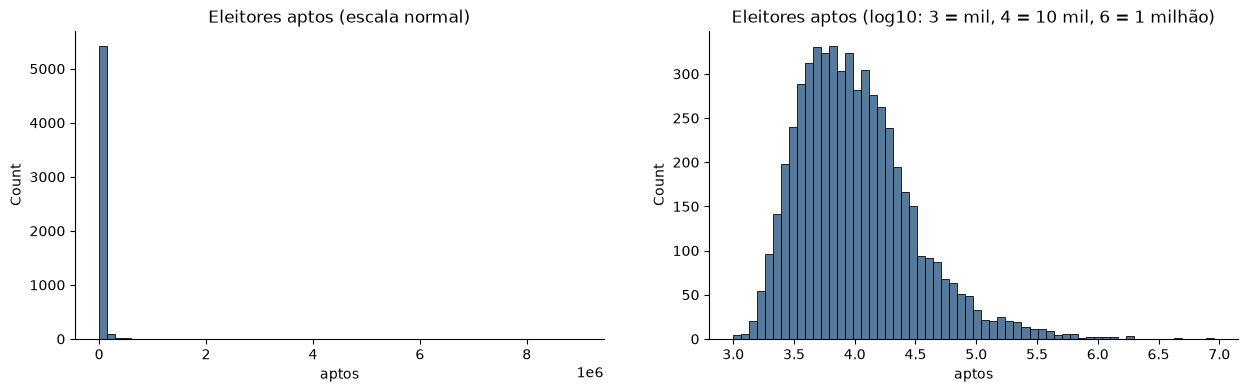

In [15]:
display(mun_prefeito.nlargest(5, 'aptos')[['uf', 'municipio', 'aptos', 'abstencao', 'candidatos']])
display(df.nlargest(5, 'votos')[['uf', 'municipio', 'cargo', 'candidato', 'partido', 'votos']])

fig, axs = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(mun_prefeito['aptos'], bins=60, color=COR_PRINCIPAL, ax=axs[0])
axs[0].set_title('Eleitores aptos (escala normal)')
sns.histplot(np.log10(mun_prefeito['aptos']), bins=60, color=COR_PRINCIPAL, ax=axs[1])
axs[1].set_title('Eleitores aptos (log10: 3 = mil, 4 = 10 mil, 6 = 1 milhão)')
sns.despine()
plt.show()

📌 **Nota**
- 🔎 O tamanho dos municípios é **muito desigual**: São Paulo tem **9 milhões** de eleitores, enquanto o menor tem **1 mil**. Na escala normal, quase todos os municípios ficam espremidos à esquerda do gráfico; na escala **log10**, a distribuição fica parecida com uma curva normal.
- 🔎 Os candidatos mais votados são prefeitos de capitais: **Bruno Covas** (1,75 milhão de votos em São Paulo) e **Guilherme Boulos** (1,08 milhão), que foram para o 2º turno.
- ✅ **Decisão:** manter todos os municípios. São valores **reais**, não erros. Para não deixar os gigantes dominarem as conclusões, usamos **mediana**, **faixas de tamanho** (`porte`) e **log10** no modelo.

### 2.7. Balanceamento dos dados

Candidatos marcados como eleitos: 12.2%


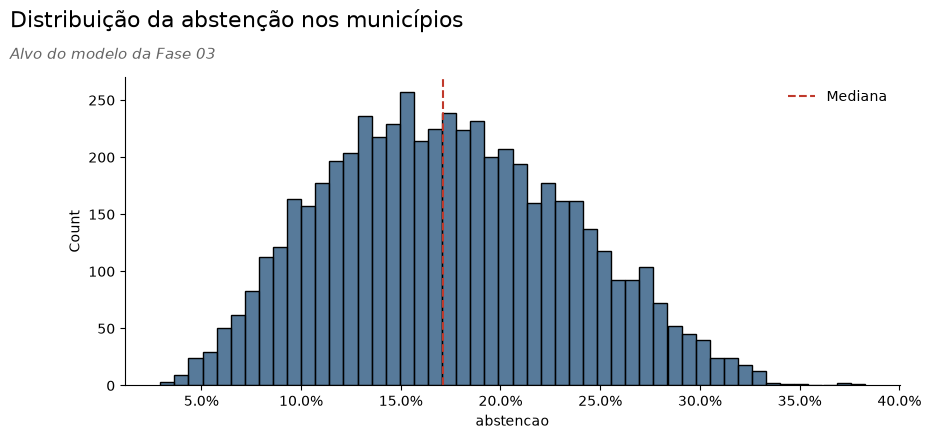

In [16]:
print(f"Candidatos marcados como eleitos: {df['eleito'].mean():.1%}")

plt.figure(figsize=(10, 4))
sns.histplot(mun_prefeito['abstencao'], bins=50, color=COR_PRINCIPAL)
plt.axvline(mun_prefeito['abstencao'].median(), color=COR_DESTAQUE, ls='--', label='Mediana')
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.legend(frameon=False)
sns.despine()
titulo('Distribuição da abstenção nos municípios', 'Alvo do modelo da Fase 03')
plt.show()

📌 **Nota**
- 🔎 **12,2%** das candidaturas foram marcadas como eleitas. Como esta análise **não classifica candidatos**, essa proporção não precisa ser balanceada.
- 🔎 O alvo do modelo da Fase 03 é a **abstenção do município**, que vai de **2,9%** a **38,3%**, com mediana de **17,1%** e formato próximo de uma curva normal.

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS (EDA)

### 3.1. Hipóteses

| # | Hipótese | Pergunta de negócio |
|---|---|---|
| **H1** | Poucos partidos concentram a **maioria dos prefeitos** eleitos | 1 |
| **H2** | Os **mesmos partidos** dominam as Câmaras de Vereadores | 1 |
| **H3** | Quem **lança mais candidatos** elege mais, mas a **taxa de sucesso** não é igual entre os partidos | 2 |
| **H4** | A **abstenção** é maior nas cidades **grandes** e nas **capitais** | 3 |
| **H5** | Os votos **brancos e nulos** crescem com o tamanho da cidade | 3 |
| **H6** | A **concorrência** (candidatos por vaga) é maior nas cidades grandes | 3 |
| **H7** | O partido do prefeito eleito costuma ter a **maior bancada** na Câmara | 4 |
| **H8** | A abstenção **varia por estado**, sendo maior no **Sudeste** | 3 |
| **H9** | O **resultado final** (2º turno e julgamentos) não muda o ranking dos partidos | 1 |
| **H10** | Entre 2016 e 2024, os partidos de **centro-direita cresceram** e os tradicionais (MDB, PSDB) encolheram | 6 |
| **H11** | A abstenção **subiu na pandemia (2020)** e não voltou ao nível de 2016 em 2024 | 6 |
| **H12** | Municípios mais **urbanos** e mais **ricos** têm mais abstenção | 3 |
| **H13** | Municípios mais atingidos pela **Covid** tiveram mais abstenção | 3 |
| **H14** | Quanto **maior a aliança** (coligação), maior a chance de eleger o prefeito | 2 |

### 3.2. Análises individuais

#### H1: Poucos partidos concentram a maioria dos prefeitos eleitos

Prefeitos eleitos no 1º turno: 5,405


,Quantidade,%,% acumulado
partido,,,
MDB,775,0.143,0.143
PP,682,0.126,0.270
PSD,650,0.120,0.390
PSDB,512,0.095,0.485
DEM,459,0.085,0.569
PL,343,0.063,0.633
PDT,311,0.058,0.690
PSB,250,0.046,0.737


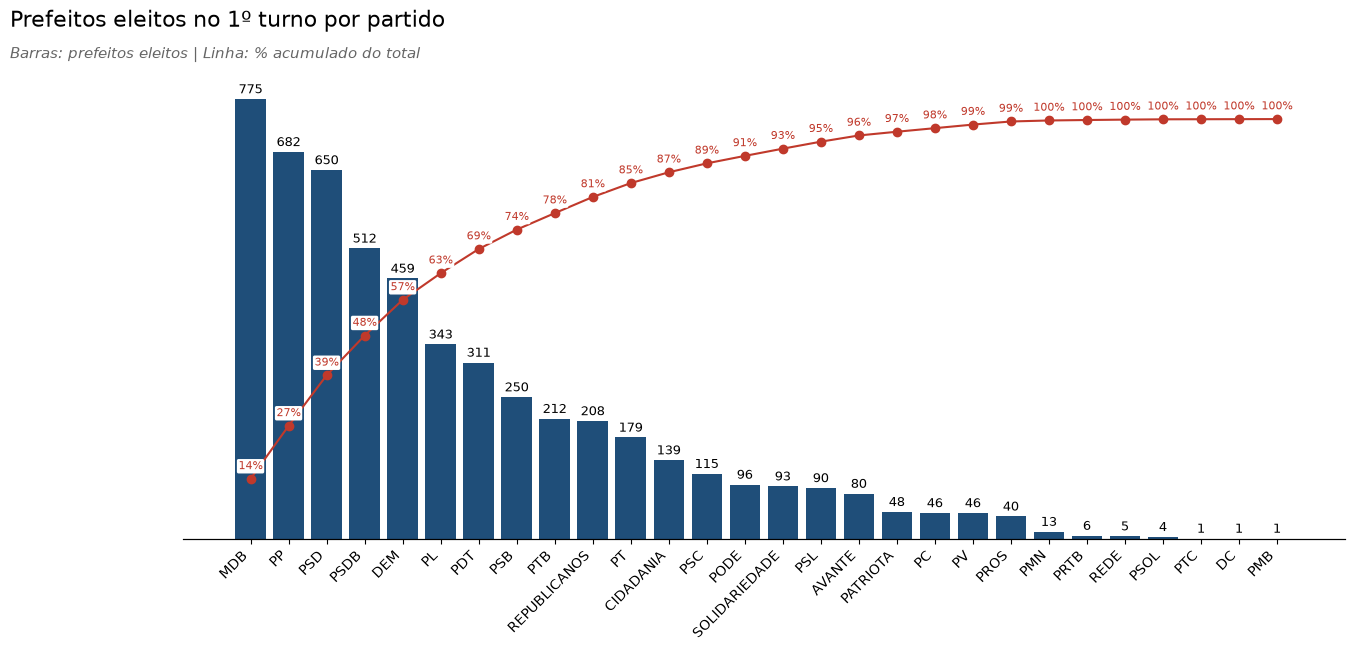

In [17]:
eleitos_prefeito = prefeitos_eleitos(df)
pareto_prefeitos = pareto(eleitos_prefeito['partido'].value_counts())
print(f'Prefeitos eleitos no 1º turno: {len(eleitos_prefeito):,}')
display(pareto_prefeitos.head(8))

plot_pareto(pareto_prefeitos, 'Prefeitos eleitos no 1º turno por partido', 'Pareto prefeitos eleitos por partido',
            subtitulo='Barras: prefeitos eleitos | Linha: % acumulado do total')

✅ **Verdadeira.** Dos **28 partidos** que elegeram prefeitos no 1º turno, apenas **5 (MDB, PP, PSD, PSDB e DEM)** ficaram com **57%** das prefeituras. O **MDB** lidera, com **775 prefeitos** (14,3%).

#### H2: Os mesmos partidos dominam as Câmaras de Vereadores

Vereadores eleitos: 57,866


,Quantidade,%,% acumulado
partido,,,
MDB,7311,0.126,0.126
PP,6331,0.109,0.236
PSD,5676,0.098,0.334
PSDB,4368,0.075,0.409
DEM,4335,0.075,0.484
PL,3464,0.060,0.544
PDT,3434,0.059,0.603
PSB,3006,0.052,0.655


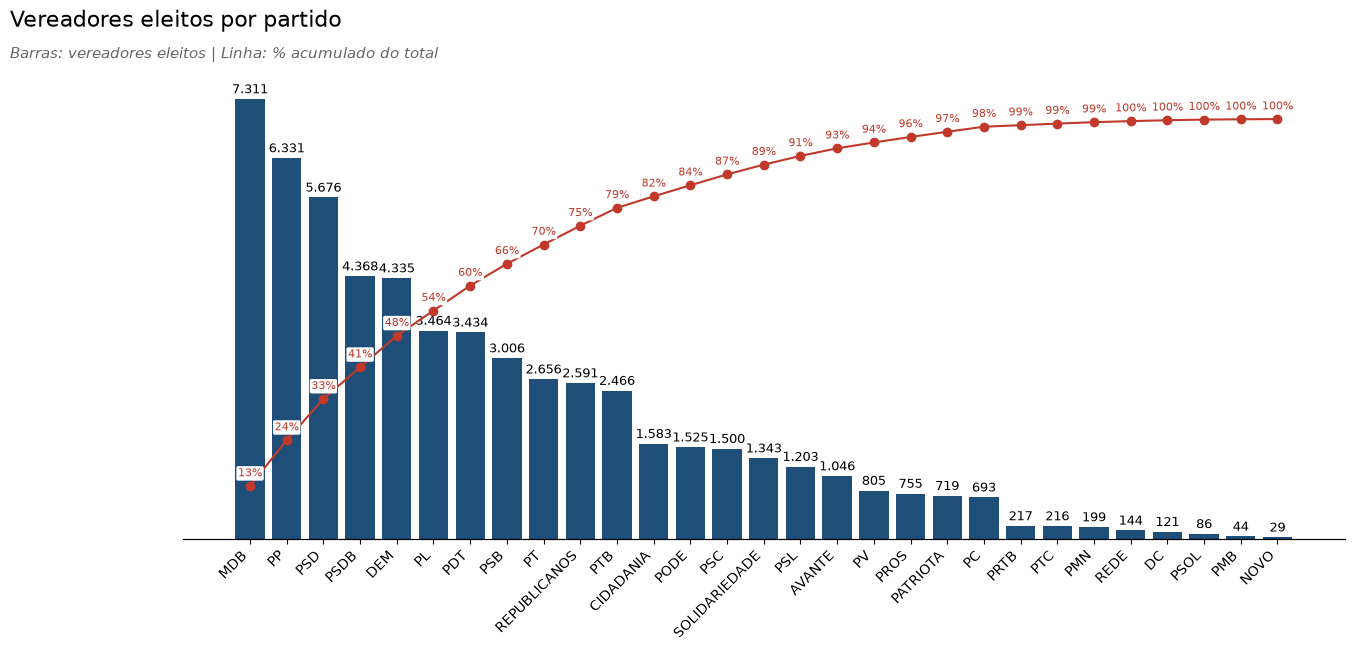

In [18]:
eleitos_vereador = df[(df['cargo'] == 'vereador') & df['eleito']]
pareto_vereadores = pareto(eleitos_vereador['partido'].value_counts())
print(f'Vereadores eleitos: {len(eleitos_vereador):,}')
display(pareto_vereadores.head(8))

plot_pareto(pareto_vereadores, 'Vereadores eleitos por partido', 'Pareto vereadores eleitos por partido',
            subtitulo='Barras: vereadores eleitos | Linha: % acumulado do total')

✅ **Verdadeira.** Os **mesmos 5 partidos**, na **mesma ordem**, elegeram **48%** dos **57.866 vereadores**. A concentração é um pouco menor que para prefeito: na eleição proporcional, partidos menores conseguem algumas cadeiras.

### 3.3. Análises combinadas

#### H3: Quem lança mais candidatos elege mais, mas com eficiência diferente

In [19]:
partidos = resumo_partidos(df)
partidos.head(12)

,candidatos_prefeito,prefeitos_eleitos,candidatos_vereador,vereadores_eleitos,sucesso_prefeito,sucesso_vereador
partido,,,,,,
MDB,1894,775,40275,7311,0.409,0.182
PP,1471,682,34687,6331,0.464,0.183
PSD,1599,650,35672,5676,0.407,0.159
PSDB,1273,512,29738,4368,0.402,0.147
DEM,1124,459,30088,4335,0.408,0.144
PL,939,343,25672,3464,0.365,0.135
PDT,931,311,25962,3434,0.334,0.132
PSB,844,250,24383,3006,0.296,0.123
PTB,726,212,21427,2466,0.292,0.115


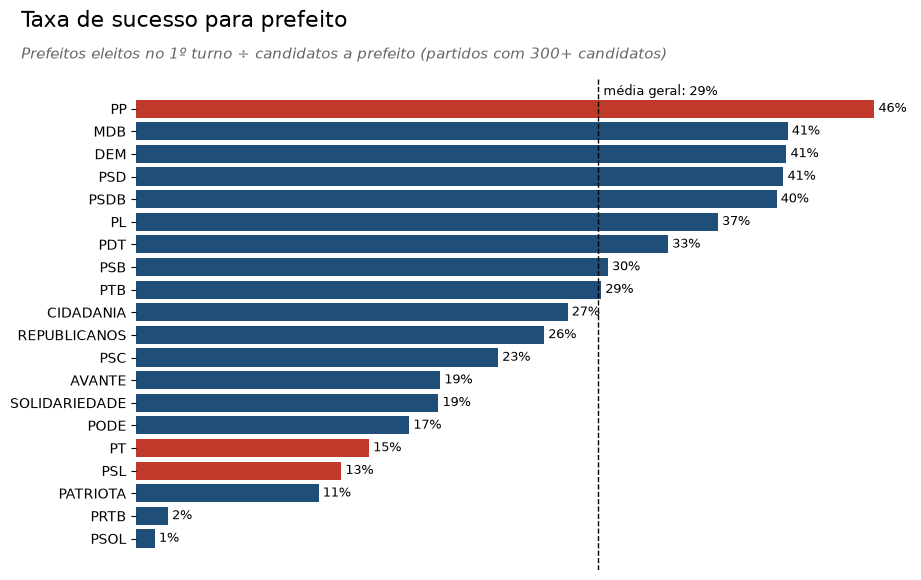

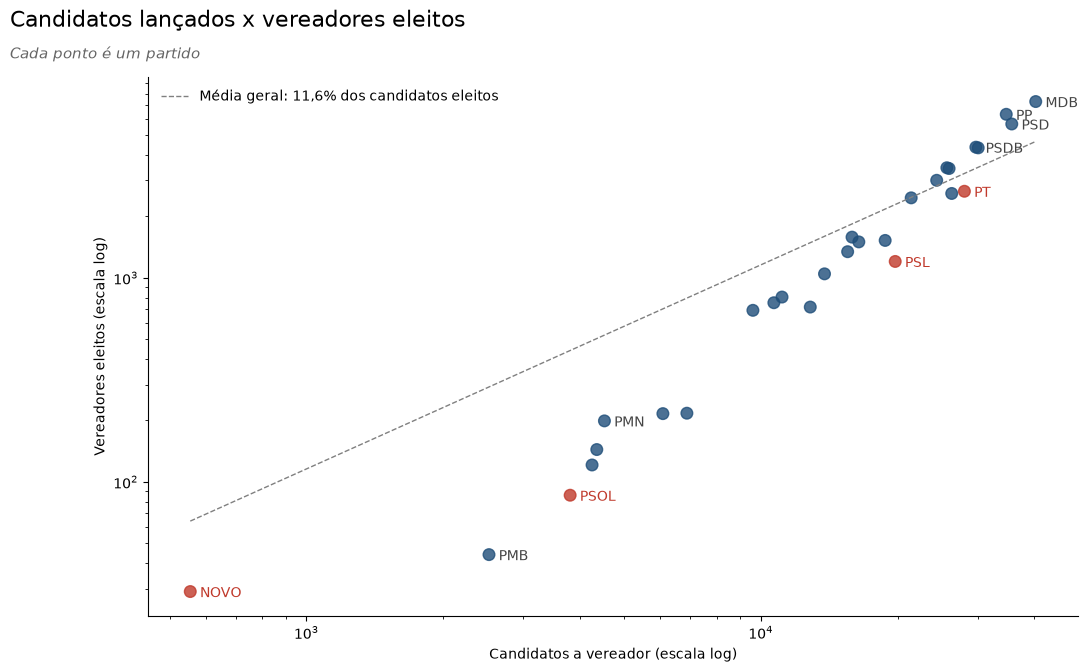

In [20]:
grandes = partidos[partidos['candidatos_prefeito'] >= 300]  # partidos com presença nacional
plot_barras_h(grandes['sucesso_prefeito'], 'Taxa de sucesso para prefeito',
              'Taxa de sucesso para prefeito por partido',
              subtitulo='Prefeitos eleitos no 1º turno ÷ candidatos a prefeito (partidos com 300+ candidatos)',
              destaque=['PT', 'PSL', 'PP'], referencia=len(eleitos_prefeito) / (df['cargo'] == 'prefeito').sum())

plot_dispersao_partidos(partidos, 'candidatos_vereador', 'vereadores_eleitos',
                        'Candidatos lançados x vereadores eleitos', 'Candidatos x vereadores eleitos por partido',
                        xlabel='Candidatos a vereador (escala log)', ylabel='Vereadores eleitos (escala log)',
                        subtitulo='Cada ponto é um partido', destaque=['PT', 'PSL', 'NOVO', 'PSOL'],
                        rotular=['MDB', 'PP', 'PSD', 'PSDB', 'PMN', 'PMB'],
                        taxa_referencia=len(eleitos_vereador) / (df['cargo'] == 'vereador').sum())

⚠️ **Parcialmente verdadeira.** Partidos que lançam mais candidatos elegem mais, mas a **eficiência** (eleitos por candidato) muda muito:
- 🔎 Em média, **29%** dos candidatos a prefeito venceram no 1º turno. O **PP** elegeu **46%** dos seus candidatos, enquanto o **PT** lançou **1.224** candidatos (o 5º que mais lançou) e elegeu só **179 (15%)**.
- 🔎 Para vereador, a média foi de **11,6%** dos candidatos eleitos. No gráfico de dispersão, os partidos **acima da linha tracejada** elegeram mais que a média por candidato: os grandes partidos de centro (MDB, PP, PSD) ficam acima, e PT, PSL e PSOL ficam abaixo.
- 💡 Lançar muitos candidatos não basta: os partidos com mais **prefeitos e estrutura local** são os mais eficientes.

#### H4: A abstenção é maior nas cidades grandes e nas capitais

,municipios,mediana
porte,,
Até 10 mil,3027,0.139
10 a 50 mil,2084,0.201
50 a 200 mil,361,0.241
Mais de 200 mil,94,0.258


,abstencao
capital,
Não capital,0.171
Capital,0.251


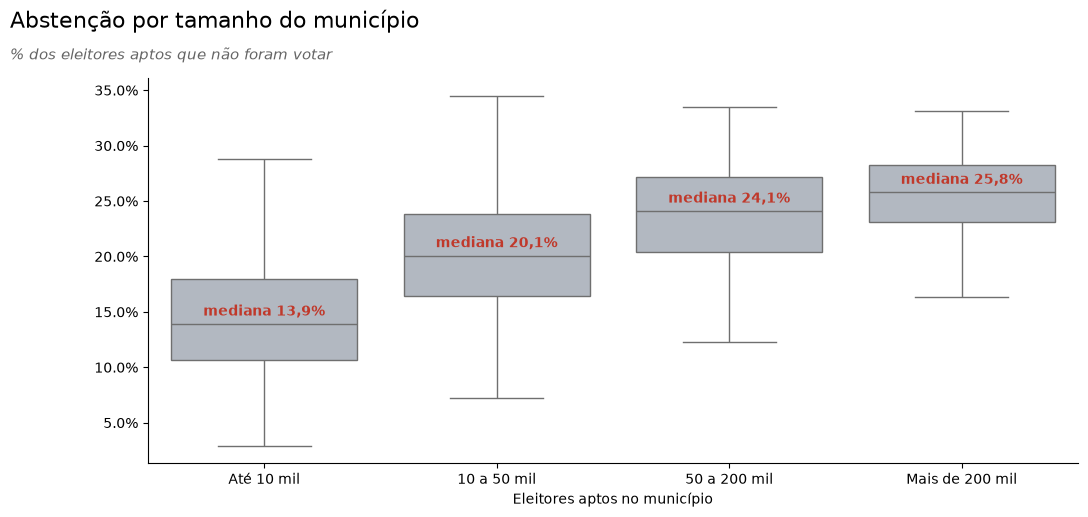

In [21]:
ORDEM_PORTE = ['Até 10 mil', '10 a 50 mil', '50 a 200 mil', 'Mais de 200 mil']

def resumo_por_porte(tabela, coluna):
    return tabela.groupby('porte', observed=True).agg(municipios=('codigo_tse', 'size'),
                                                      mediana=(coluna, 'median'))

def box_por_porte(tabela, coluna, titulo_grafico, nome_arquivo, subtitulo=None):
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=tabela, x='porte', y=coluna, order=ORDEM_PORTE, color=COR_NEUTRA, showfliers=False)
    medianas = tabela.groupby('porte', observed=True)[coluna].median().reindex(ORDEM_PORTE)
    for i, valor in enumerate(medianas):
        plt.annotate(f'mediana {pct(valor, 1)}', (i, valor), xytext=(0, 6), textcoords='offset points',
                     ha='center', color=COR_DESTAQUE, fontsize=10, weight='bold')
    plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    plt.xlabel('Eleitores aptos no município')
    plt.ylabel('')
    sns.despine()
    titulo(titulo_grafico, subtitulo)
    salvar(nome_arquivo)
    plt.show()

display(resumo_por_porte(mun_prefeito, 'abstencao'))
display(mun_prefeito.groupby('capital')['abstencao'].median().rename({0: 'Não capital', 1: 'Capital'}).to_frame())
box_por_porte(mun_prefeito, 'abstencao', 'Abstenção por tamanho do município', 'Abstencao por porte do municipio',
              subtitulo='% dos eleitores aptos que não foram votar')

✅ **Verdadeira.** A abstenção mediana sobe de forma contínua com o tamanho do município: **13,9%** nas cidades com até 10 mil eleitores, **20,1%** entre 10 e 50 mil, **24,1%** entre 50 e 200 mil e **25,8%** acima de 200 mil. Nas **capitais**, a mediana foi de **25,1%**, contra **17,1%** nas demais cidades.

> 💡 Em cidades pequenas, o eleitor conhece pessoalmente os candidatos e o local de votação costuma ser perto de casa. Nas grandes cidades, a distância, o transporte e o medo da Covid pesaram mais.

#### H5: Os votos brancos e nulos crescem com o tamanho da cidade

,municipios,mediana,mediana vereador
porte,,,
Até 10 mil,3027,0.041,0.039
10 a 50 mil,2084,0.055,0.051
50 a 200 mil,361,0.093,0.078
Mais de 200 mil,94,0.125,0.117


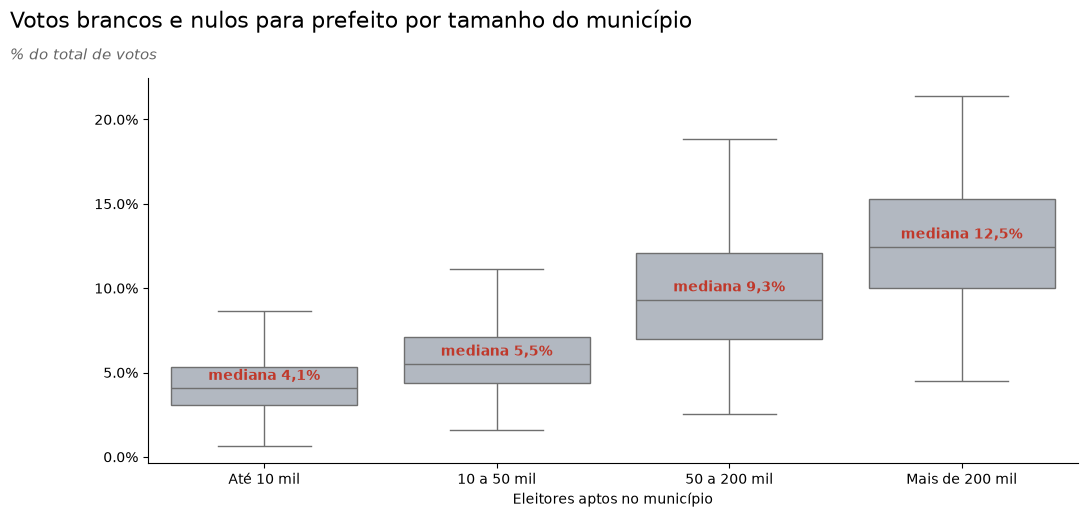

In [22]:
display(resumo_por_porte(mun_prefeito, 'brancos_nulos').join(
    resumo_por_porte(mun_vereador, 'brancos_nulos')['mediana'].rename('mediana vereador')))
box_por_porte(mun_prefeito, 'brancos_nulos', 'Votos brancos e nulos para prefeito por tamanho do município',
              'Brancos e nulos por porte do municipio', subtitulo='% do total de votos')

✅ **Verdadeira.** A mediana de votos brancos e nulos para prefeito **triplica**: de **4,1%** nas cidades com até 10 mil eleitores para **12,5%** nas cidades com mais de 200 mil. O mesmo acontece para vereador (de 3,9% para 11,7%).

#### H6: A concorrência é maior nas cidades grandes

,prefeito,vereador
porte,,
Até 10 mil,2.000,4.444
10 a 50 mil,3.000,8.273
50 a 200 mil,6.000,17.706
Mais de 200 mil,10.000,26.386


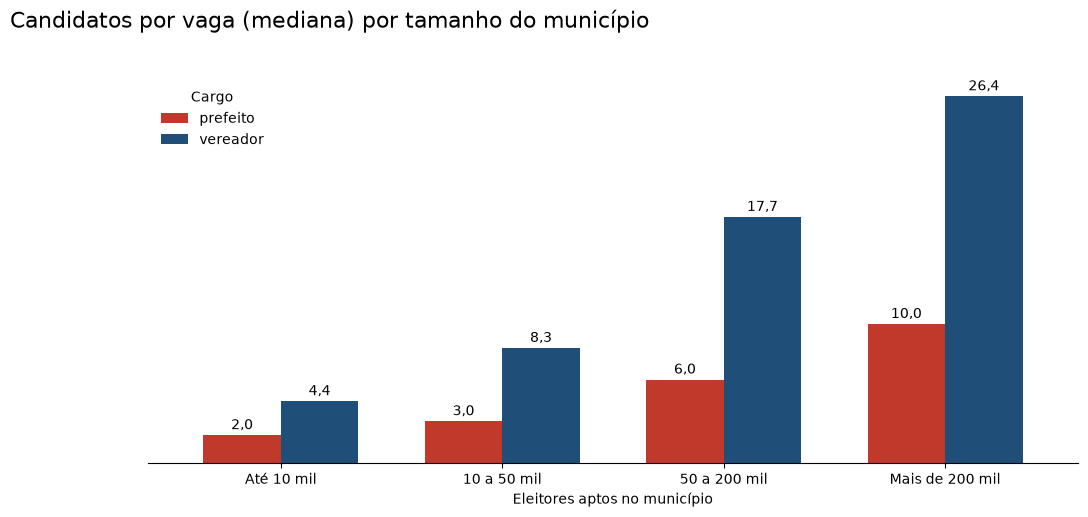

In [23]:
concorrencia = pd.DataFrame({
    'prefeito': mun_prefeito.groupby('porte', observed=True)['candidatos_por_vaga'].median(),
    'vereador': mun_vereador.groupby('porte', observed=True)['candidatos_por_vaga'].median(),
})
display(concorrencia)

ax = concorrencia.plot.bar(figsize=(12, 5), color=[COR_DESTAQUE, COR_PRINCIPAL], rot=0, width=0.7)
for barras in ax.containers:
    ax.bar_label(barras, fmt=lambda v: f'{v:.1f}'.replace('.', ','), padding=2)
ax.set_xlabel('Eleitores aptos no município')
ax.set_yticks([])
ax.legend(title='Cargo', frameon=False)
sns.despine(left=True)
titulo('Candidatos por vaga (mediana) por tamanho do município')
salvar('Candidatos por vaga por porte do municipio')
plt.show()

✅ **Verdadeira.** Nas cidades com até 10 mil eleitores, a mediana é de **2 candidatos a prefeito** e **4,4 candidatos por vaga de vereador**. Nas cidades com mais de 200 mil, são **10 candidatos a prefeito** e **26,4 por vaga** de vereador.

#### H7: O partido do prefeito eleito costuma ter a maior bancada na Câmara

Partido do prefeito tem a maior bancada (ou empata): 66.7%
Partido do prefeito não elegeu nenhum vereador: 5.9%
Mediana das cadeiras do partido do prefeito: 33.3%


,municipios,maior_bancada,cadeiras_mediana
porte,,,
Até 10 mil,2978,0.667,0.333
10 a 50 mil,2040,0.668,0.273
50 a 200 mil,352,0.651,0.182
Mais de 200 mil,35,0.886,0.185


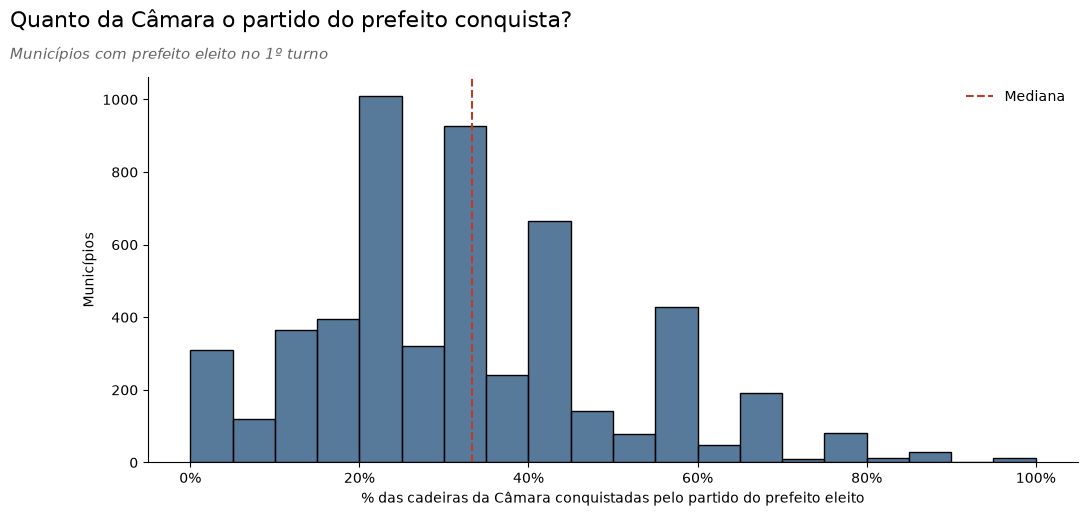

In [24]:
bancada = bancada_do_prefeito(df)
bancada['porte'] = classificar_porte(bancada['aptos'])

print(f"Partido do prefeito tem a maior bancada (ou empata): {bancada['maior_bancada_e_do_prefeito'].mean():.1%}")
print(f"Partido do prefeito não elegeu nenhum vereador: {(bancada['cadeiras'] == 0).mean():.1%}")
print(f"Mediana das cadeiras do partido do prefeito: {bancada['% cadeiras'].median():.1%}")
display(bancada.groupby('porte', observed=True).agg(municipios=('codigo_tse', 'size'),
                                                    maior_bancada=('maior_bancada_e_do_prefeito', 'mean'),
                                                    cadeiras_mediana=('% cadeiras', 'median')))

plt.figure(figsize=(12, 5))
sns.histplot(bancada['% cadeiras'], bins=np.arange(0, 1.05, 0.05), color=COR_PRINCIPAL)
plt.axvline(bancada['% cadeiras'].median(), color=COR_DESTAQUE, ls='--', label='Mediana')
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xlabel('% das cadeiras da Câmara conquistadas pelo partido do prefeito eleito')
plt.ylabel('Municípios')
plt.legend(frameon=False)
sns.despine()
titulo('Quanto da Câmara o partido do prefeito conquista?', 'Municípios com prefeito eleito no 1º turno')
salvar('Bancada do partido do prefeito')
plt.show()

✅ **Verdadeira.** Em **66,7%** dos municípios, o partido do prefeito eleito ficou com a **maior bancada** da Câmara (sozinho ou empatado). Nas cidades com mais de 200 mil eleitores, isso acontece em **88,6%** dos casos (31 de 35).

🔎 Mas maior bancada **não é maioria**: a mediana é de apenas **33%** das cadeiras, e em **5,9%** dos municípios o partido do prefeito **não elegeu nenhum vereador**. Ou seja, o prefeito quase sempre precisa de **alianças** para aprovar projetos na Câmara.

#### H8: A abstenção varia por estado

,abstencao
regiao,
Nordeste,0.185
Norte,0.206
Sul,0.232
Centro-Oeste,0.243
Sudeste,0.263


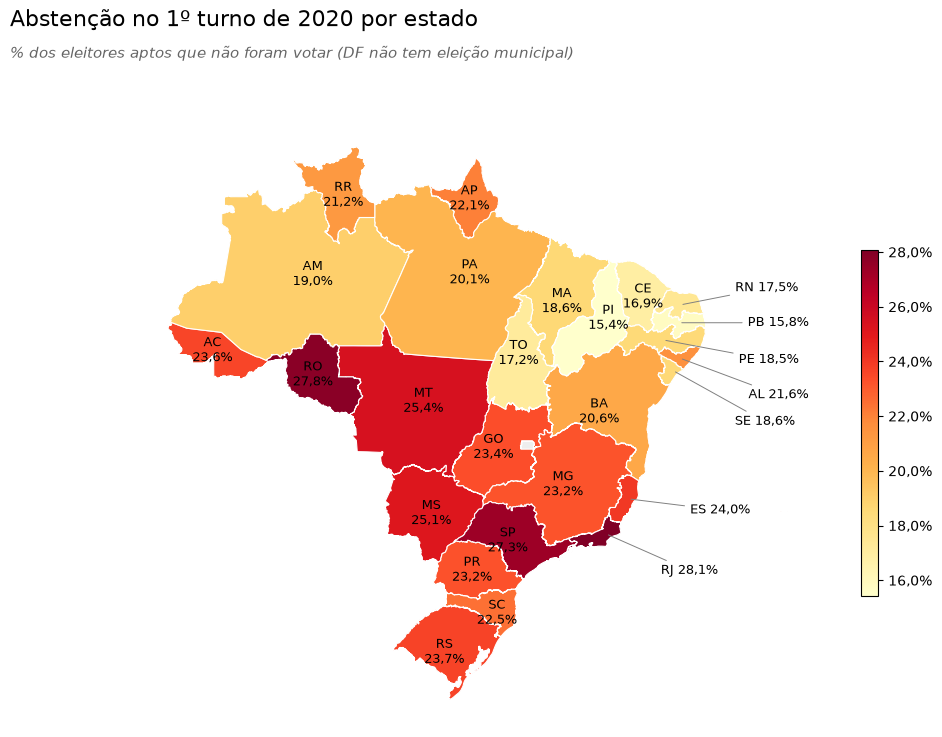

In [25]:
abstencao_uf = mun_prefeito.groupby('uf')[['abstencoes', 'aptos']].sum()
abstencao_uf['abstencao'] = abstencao_uf['abstencoes'] / abstencao_uf['aptos']
abstencao_uf['regiao'] = abstencao_uf.index.map(REGIAO_DA_UF)
display(abstencao_uf.groupby('regiao')[['abstencoes', 'aptos']].sum().pipe(
    lambda t: (t['abstencoes'] / t['aptos']).sort_values().to_frame('abstencao')))

mapa = gpd.read_file('../Datasets/uf.json').rename(columns={'UF_05': 'uf'})[['uf', 'geometry']]
mapa = mapa.merge(abstencao_uf['abstencao'], left_on='uf', right_index=True, how='left')
plot_mapa_uf(mapa, 'abstencao', 'Abstenção no 1º turno de 2020 por estado', 'Mapa da abstencao por UF',
             subtitulo='% dos eleitores aptos que não foram votar (DF não tem eleição municipal)', formato=lambda v: pct(v, 1))

✅ **Verdadeira.** A abstenção vai de **15,4%** no **Piauí** a **28,1%** no **Rio de Janeiro**. Por região: **Nordeste 18,5%**, Norte 20,6%, Sul 23,2%, Centro-Oeste 24,3% e **Sudeste 26,3%**. Os 3 estados com menor abstenção são do Nordeste: **PI, PB e CE**.

> 💡 Parte dessa diferença vem do tamanho das cidades (o Nordeste tem muitos municípios pequenos), mas não toda: o modelo da Fase 03 mostra que o **estado** continua importante mesmo comparando cidades de mesmo tamanho.

#### H9: O resultado final não muda o ranking dos partidos

A base principal tem só o 1º turno. O arquivo de candidatos do TSE registra o **resultado final**: quem venceu o 2º turno e a situação dos candidatos sub judice depois do julgamento.

In [26]:
final_2020 = prefeitos_final[prefeitos_final['ano'] == 2020]
print(f"Prefeitos com resultado final em 2020: {len(final_2020):,} "
      f"(1º turno: {(final_2020['turno'] == 1).sum():,} | 2º turno: {(final_2020['turno'] == 2).sum()})")

sub_judice = situacao[situacao == 'Indefinido (sub judice)'].index
print(f"Municípios sub judice com prefeito eleito registrado depois: {final_2020['codigo_tse'].isin(sub_judice).sum()} "
      f"de {len(sub_judice)}")

print('Vencedores do 2º turno por partido:')
display(final_2020.loc[final_2020['turno'] == 2, 'partido_original'].value_counts().head(8).to_frame('prefeitos'))

pareto_final = pareto(final_2020['partido_original'].value_counts())
comparacao_ranking = pareto_prefeitos[['Quantidade']].join(pareto_final[['Quantidade']], lsuffix=' (1º turno)',
                                                          rsuffix=' (final)', how='outer').fillna(0).astype(int)
comparacao_ranking.sort_values('Quantidade (final)', ascending=False).head(8)

Prefeitos com resultado final em 2020: 5,494 (1º turno: 5,436 | 2º turno: 58)
Municípios sub judice com prefeito eleito registrado depois: 53 de 104
Vencedores do 2º turno por partido:


,prefeitos
partido_original,
MDB,10
PSDB,8
PODE,6
DEM,5
PSD,5
PT,4
REPUBLICANOS,3
PP,3


,Quantidade (1º turno),Quantidade (final)
partido,,
MDB,775,793
PP,682,690
PSD,650,657
PSDB,512,523
DEM,459,469
PL,343,343
PDT,311,314
PSB,250,253


⚠️ **Verdadeira para o ranking, mas o resultado final completa o quadro.**
- 🔎 Com o resultado final, **5.494** municípios têm prefeito eleito em 2020: **5.436** decididos no 1º turno (incluindo casos sub judice resolvidos depois) e **58** no 2º turno.
- 🔎 Dos **104** municípios sub judice, **53** tiveram um prefeito eleito registrado depois do julgamento; nos demais, o cargo foi decidido em **eleição suplementar**, que não entra nesta base.
- 🔎 O **MDB** venceu mais disputas de 2º turno (**10**), seguido do PSDB (8) e do Podemos (6).
- ✅ O ranking não muda: os 5 primeiros continuam **MDB, PP, PSD, PSDB e DEM**. O resultado final só acrescenta alguns prefeitos a cada partido (o MDB vai de 775 para **793**).

#### H10: Como os partidos mudaram de 2016 para 2024

Para comparar eleições, os partidos que **se fundiram ou mudaram de nome** são somados com o nome atual (função `partido_atual`):

| Nome atual | Partidos somados |
|---|---|
| **UNIÃO** | DEM + PSL (fusão em 2022) |
| **PRD** | PTB + Patriota (fusão em 2023) |
| **PODE** | Podemos + PSC + PHS (incorporações) |
| **SOLIDARIEDADE** | Solidariedade + PROS |
| **MDB**, **PL**, **REPUBLICANOS**, **CIDADANIA** | PMDB, PR, PRB e PPS (mudanças de nome) |

ano,2016,2020,2024,variação 2016-2024
partido,,,,
PSD,538,657,886,348
MDB,1044,793,859,-185
PP,494,690,747,253
UNIÃO,297,560,588,291
PL,297,343,515,218
REPUBLICANOS,105,212,433,328
PSB,406,253,311,-95
PSDB,799,523,271,-528
PT,254,182,252,-2


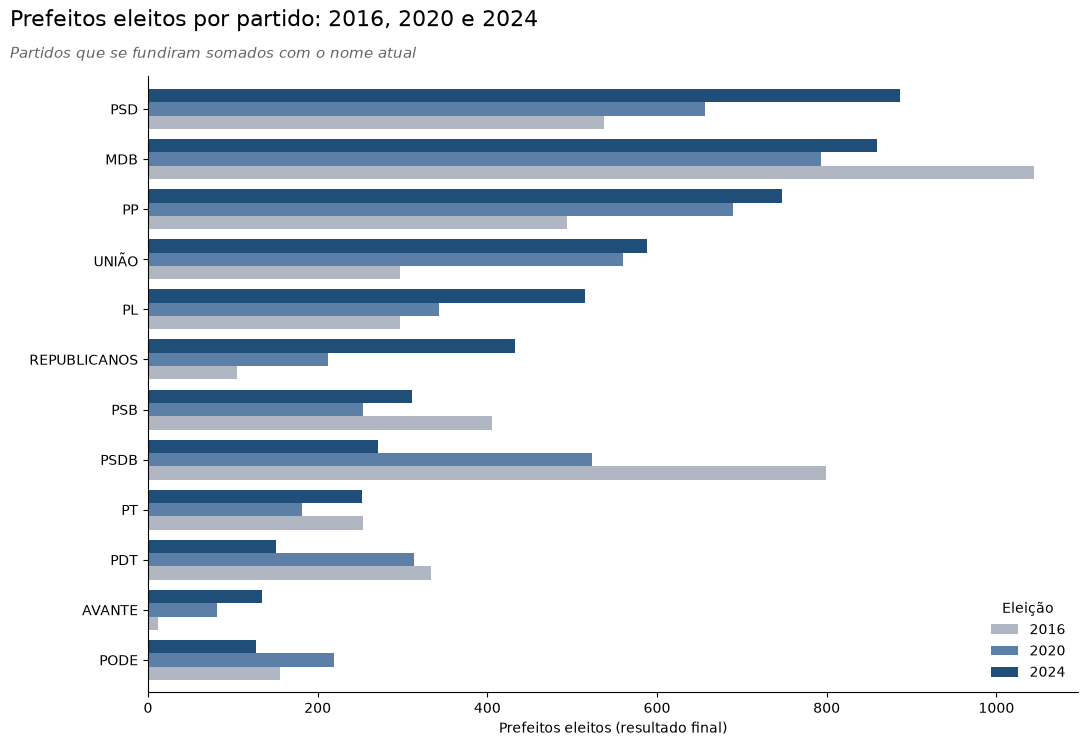

In [27]:
evolucao = prefeitos_final.pivot_table(index='partido', columns='ano', aggfunc='size', fill_value=0)
evolucao['variação 2016-2024'] = evolucao[2024] - evolucao[2016]
evolucao = evolucao.sort_values(2024, ascending=False)
display(evolucao.head(12))

top = evolucao.head(12)[[2016, 2020, 2024]].iloc[::-1]
ax = top.plot.barh(figsize=(12, 8), color=['#B0B7C3', '#5B7FA6', COR_PRINCIPAL], width=0.8)
ax.set_xlabel('Prefeitos eleitos (resultado final)')
ax.set_ylabel('')
ax.legend(title='Eleição', frameon=False, loc='lower right')
sns.despine()
titulo('Prefeitos eleitos por partido: 2016, 2020 e 2024', 'Partidos que se fundiram somados com o nome atual')
salvar('Prefeitos eleitos por partido 2016 2020 2024')
plt.show()

✅ **Verdadeira.** Entre 2016 e 2024 houve uma grande troca de forças no poder local:
- 🔎 **Cresceram:** **PSD** (538 → **886** prefeitos, o maior partido em 2024), **Republicanos** (105 → 433), **UNIÃO** (DEM + PSL: 297 → 588), **PP** (494 → 747) e **PL** (297 → 515).
- 🔎 **Encolheram:** **PSDB** (799 → **271**, perdeu 2 de cada 3 prefeituras), **MDB** (1.044 → 859, deixou de ser o maior), **PRD** (PTB + Patriota: 287 → 77) e **PDT** (334 → 151).
- 🔎 O **PT** ficou estável (254 → 252), depois de cair para 182 em 2020.

#### H11: A abstenção subiu na pandemia e não voltou ao nível de 2016

,abstencoes,aptos,abstencao
ano,,,
2016,25330516,144083689,0.176
2020,34242550,147918483,0.231
2024,33790473,155881768,0.217


ano,2016,2020,2024
porte,,,
Até 10 mil,0.118,0.139,0.137
10 a 50 mil,0.174,0.201,0.179
50 a 200 mil,0.184,0.241,0.226
Mais de 200 mil,0.187,0.258,0.247


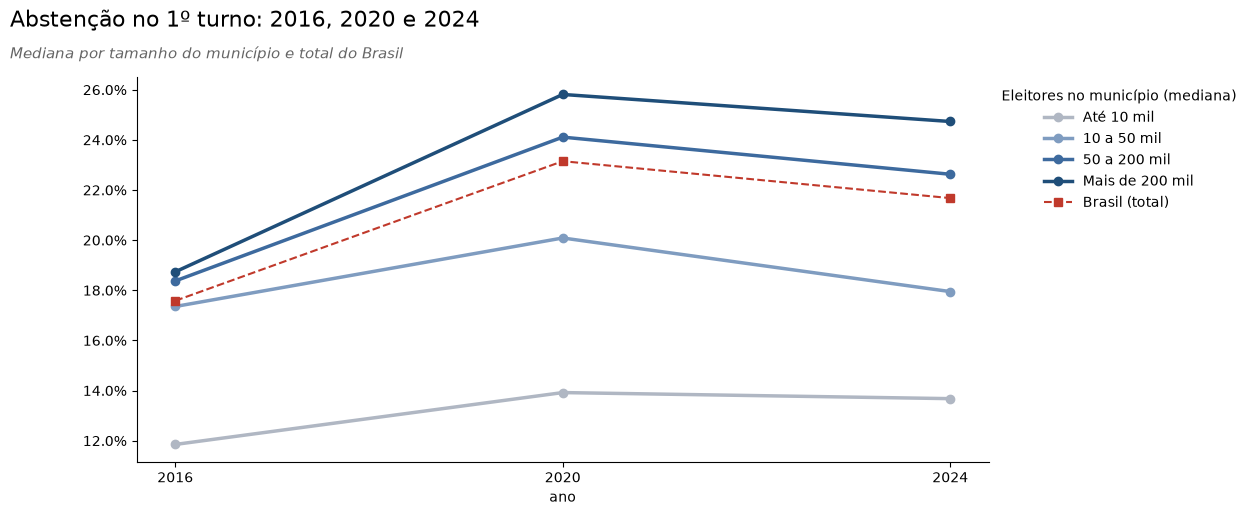

In [28]:
nacional = painel.groupby('ano')[['abstencoes', 'aptos']].sum()
nacional['abstencao'] = nacional['abstencoes'] / nacional['aptos']
display(nacional)

painel['porte'] = classificar_porte(painel['aptos'])
por_porte_ano = painel.pivot_table(index='porte', columns='ano', values='abstencao', aggfunc='median', observed=True)
display(por_porte_ano)

ax = por_porte_ano.T.plot(figsize=(11, 5), marker='o', lw=2.5,
                          color=['#B0B7C3', '#7F9CC0', '#3D6A9E', COR_PRINCIPAL])
ax.plot(nacional.index, nacional['abstencao'], color=COR_DESTAQUE, ls='--', marker='s', label='Brasil (total)')
ax.set_xticks([2016, 2020, 2024])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(title='Eleitores no município (mediana)', frameon=False, bbox_to_anchor=(1, 1))
sns.despine()
titulo('Abstenção no 1º turno: 2016, 2020 e 2024', 'Mediana por tamanho do município e total do Brasil')
salvar('Abstencao 2016 2020 2024')
plt.show()

✅ **Verdadeira.** A abstenção no Brasil foi de **17,6%** em 2016, subiu para **23,1%** em 2020 (pandemia) e caiu para **21,7%** em 2024, ainda **4 p.p. acima** de 2016.
- 🔎 O padrão vale para todos os tamanhos de cidade, mas a "volta" em 2024 foi pequena nas cidades grandes: acima de 200 mil eleitores, a mediana foi de **18,7%** (2016) para **25,8%** (2020) e **24,7%** (2024).
- 💡 Isso indica que parte do aumento de 2020 **não foi só efeito da pandemia**: o eleitor de cidade grande passou a votar menos.

#### H12: Municípios mais urbanos e mais ricos têm mais abstenção

Dividimos os municípios de 2020 em **5 grupos do mesmo tamanho** (quintis) para cada indicador do IBGE e comparamos a abstenção mediana de cada grupo.

,% população urbana,PIB per capita,% população com 60+,Eleitores por habitante
1 (menor),0.135,0.162,0.184,0.198
2,0.154,0.162,0.171,0.189
3,0.164,0.178,0.177,0.181
4,0.183,0.178,0.173,0.157
5 (maior),0.226,0.181,0.140,0.126


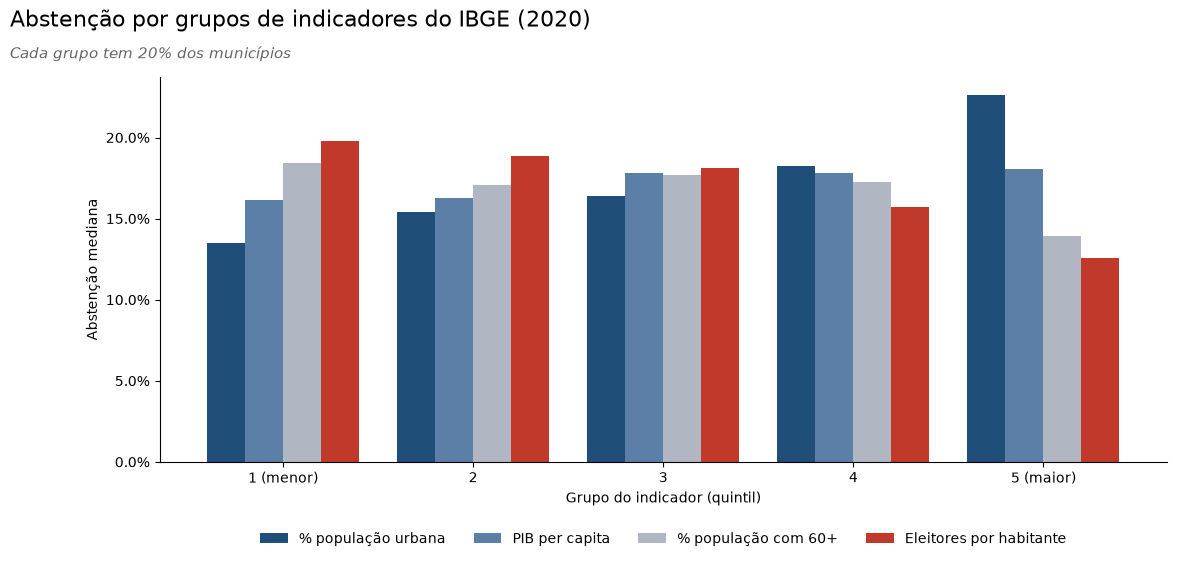

In [29]:
painel_2020 = painel[painel['ano'] == 2020].copy()
indicadores = {'pct_urbana': '% população urbana', 'pib_per_capita': 'PIB per capita',
               'pct_idosos': '% população com 60+', 'eleitores_por_habitante': 'Eleitores por habitante'}
GRUPOS = ['1 (menor)', '2', '3', '4', '5 (maior)']

quintis = pd.DataFrame({nome: painel_2020.groupby(pd.qcut(painel_2020[coluna], 5, labels=GRUPOS),
                                                  observed=True)['abstencao'].median()
                        for coluna, nome in indicadores.items()})
display(quintis)

ax = quintis.plot.bar(figsize=(13, 5), rot=0, width=0.8, color=[COR_PRINCIPAL, '#5B7FA6', '#B0B7C3', COR_DESTAQUE])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel('Grupo do indicador (quintil)')
ax.set_ylabel('Abstenção mediana')
ax.legend(frameon=False, ncols=4, loc='upper center', bbox_to_anchor=(0.5, -0.15))
sns.despine()
titulo('Abstenção por grupos de indicadores do IBGE (2020)', 'Cada grupo tem 20% dos municípios')
salvar('Abstencao por indicadores do IBGE')
plt.show()

⚠️ **Parcialmente verdadeira.**
- ✅ **Urbanização:** a abstenção mediana sobe de **13,5%** nos municípios mais rurais para **22,6%** nos mais urbanos, o efeito mais forte entre os indicadores do IBGE.
- ⚠️ **Renda:** o efeito do PIB per capita é pequeno (de **16,2%** para **18,1%**).
- 🔎 **Idosos:** ao contrário do que se esperaria na pandemia, os municípios com **mais idosos** tiveram **menos** abstenção (**14,0%**, contra 18,4%). São, em geral, cidades pequenas e rurais, onde a abstenção já é menor.
- 🔎 **Eleitores por habitante:** os municípios com mais eleitores por morador também tiveram **menos** abstenção (**12,6%**, contra 19,8%), outro padrão comum das cidades pequenas.
- 💡 Vários indicadores andam junto com o **tamanho da cidade**. O modelo da Fase 03 separa o efeito de cada um.

#### H13: Municípios mais atingidos pela Covid tiveram mais abstenção

,Óbitos por 100 mil (acumulado),Casos por 100 mil (acumulado),Casos por 100 mil (2 semanas antes)
1 (menor),0.143,0.163,0.149
2,0.176,0.172,0.169
3,0.175,0.172,0.179
4,0.182,0.174,0.185
5 (maior),0.176,0.172,0.175


,abstencao
obitos_100k,0.170
casos_100k,0.050
casos_14d_100k,0.150
abstencao,1.000


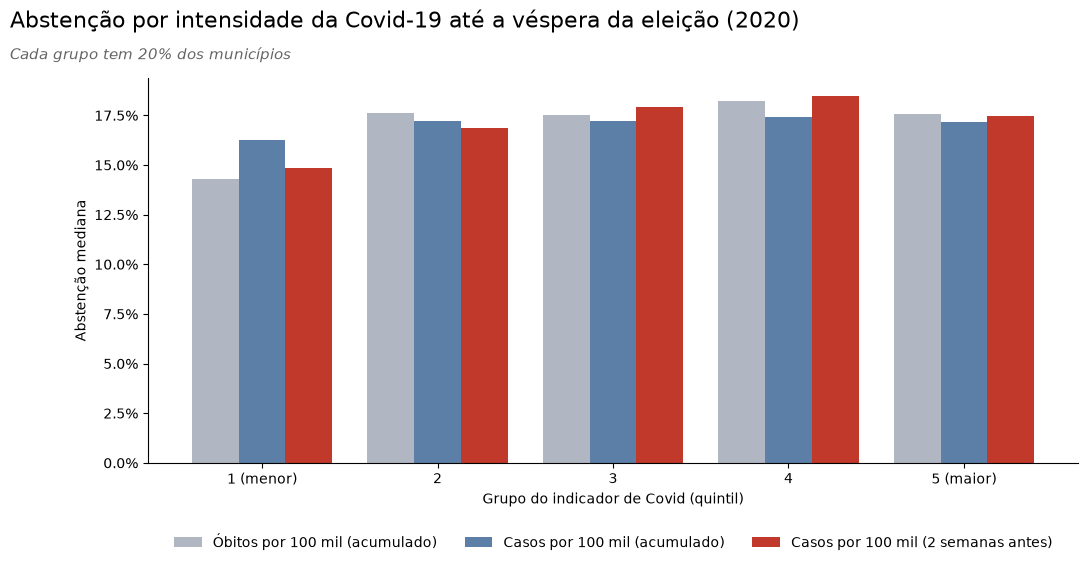

In [30]:
indicadores_covid = {'obitos_100k': 'Óbitos por 100 mil (acumulado)', 'casos_100k': 'Casos por 100 mil (acumulado)',
                     'casos_14d_100k': 'Casos por 100 mil (2 semanas antes)'}
quintis_covid = pd.DataFrame({nome: painel_2020.groupby(pd.qcut(painel_2020[coluna].rank(method='first'), 5,
                                                                labels=GRUPOS), observed=True)['abstencao'].median()
                              for coluna, nome in indicadores_covid.items()})
display(quintis_covid)
display(painel_2020[list(indicadores_covid) + ['abstencao']].corr(method='spearman')['abstencao'].round(2).to_frame())

ax = quintis_covid.plot.bar(figsize=(12, 5), rot=0, width=0.8, color=['#B0B7C3', '#5B7FA6', COR_DESTAQUE])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel('Grupo do indicador de Covid (quintil)')
ax.set_ylabel('Abstenção mediana')
ax.legend(frameon=False, ncols=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
sns.despine()
titulo('Abstenção por intensidade da Covid-19 até a véspera da eleição (2020)', 'Cada grupo tem 20% dos municípios')
salvar('Abstencao por intensidade da Covid')
plt.show()

⚠️ **Fraca.** A Covid explica pouco da abstenção quando comparamos municípios:
- 🔎 A correlação com a abstenção é baixa: **0,17** para óbitos acumulados, **0,15** para casos nas 2 semanas antes da eleição e **0,05** para casos acumulados.
- 🔎 Por quintis, só o grupo com **menos óbitos** se destaca (abstenção mediana de **14,3%**, contra cerca de **17,5%** nos demais). Esse grupo reúne muitas cidades pequenas, sem óbitos registrados, onde a abstenção já é menor: os óbitos também crescem com o tamanho da cidade (correlação de **0,31**).
- 💡 A pandemia aumentou a abstenção **no país todo** (H11), mas, dentro de 2020, os municípios mais atingidos não faltaram muito mais do que os outros. O medo parece ter sido **geral**, não proporcional aos casos locais.

#### H14: Quanto maior a aliança, maior a chance de eleger o prefeito

Em 2020, as coligações eram permitidas **só para prefeito**. O campo `coligacao` traz a composição da aliança de cada candidato (ex.: `PP - PP / PL / PTC` = 3 partidos). Usamos os municípios com resultado no 1º turno e comparamos a **taxa de vitória** com a **chance esperada** se todos os candidatos tivessem a mesma chance (1 ÷ nº de candidatos na cidade).

,candidatos,taxa_vitoria,chance_esperada,vitória / esperada
tamanho_alianca,,,,
1,5981,0.090,0.260,0.345
2,4641,0.321,0.333,0.965
3,3028,0.419,0.347,1.207
4,1681,0.485,0.337,1.441
5,986,0.529,0.311,1.703
6,526,0.548,0.313,1.752
7,320,0.572,0.295,1.939
8+,453,0.667,0.274,2.432


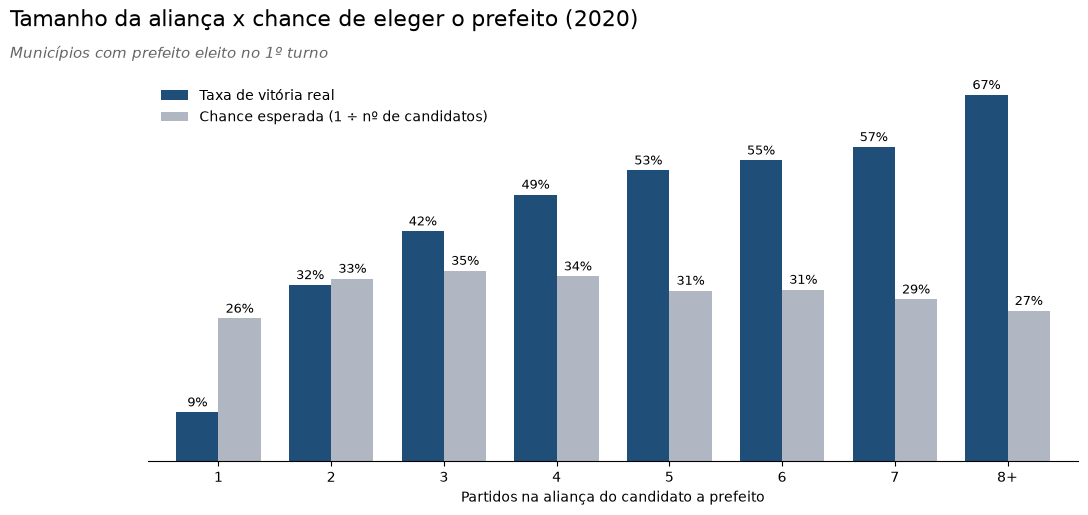

Pares de partidos que mais venceram juntos:


MDB + PP      534
PP + PSD      476
DEM + PSDB    472
MDB + PSD     441
PP + PSDB     429
MDB + PSDB    425
DEM + PP      423
PSD + PSDB    422
DEM + MDB     415
DEM + PSD     395
Name: prefeituras, dtype: int64

In [31]:
coligacoes = resumo_coligacoes(df)
coligacoes['tamanho_alianca'] = coligacoes['n_partidos'].clip(upper=8).map(lambda n: '8+' if n == 8 else str(n))
por_tamanho = coligacoes.groupby('tamanho_alianca').agg(candidatos=('eleito', 'size'), taxa_vitoria=('eleito', 'mean'),
                                                        chance_esperada=('chance_esperada', 'mean'))
por_tamanho['vitória / esperada'] = por_tamanho['taxa_vitoria'] / por_tamanho['chance_esperada']
display(por_tamanho)

ax = por_tamanho[['taxa_vitoria', 'chance_esperada']].plot.bar(figsize=(12, 5), rot=0, width=0.75,
                                                               color=[COR_PRINCIPAL, COR_NEUTRA])
for barras in ax.containers:
    ax.bar_label(barras, fmt=lambda v: pct(v), padding=2, fontsize=9)
ax.set_xlabel('Partidos na aliança do candidato a prefeito')
ax.set_yticks([])
ax.legend(['Taxa de vitória real', 'Chance esperada (1 ÷ nº de candidatos)'], frameon=False)
sns.despine(left=True)
titulo('Tamanho da aliança x chance de eleger o prefeito (2020)', 'Municípios com prefeito eleito no 1º turno')
salvar('Coligacoes tamanho da alianca')
plt.show()

print('Pares de partidos que mais venceram juntos:')
pares_vencedores(coligacoes)

✅ **Verdadeira, com cautela.**
- 🔎 Quem concorreu **sozinho** (34% dos candidatos) venceu só **9,0%** das vezes, bem abaixo da chance esperada de **26%** se todos tivessem a mesma chance.
- 🔎 A taxa de vitória cresce com o tamanho da aliança: **42%** com 3 partidos, **53%** com 5 e **67%** com 8 ou mais, mais que o **dobro** da chance esperada (27%).
- 🔎 Os pares que mais venceram juntos são dos partidos grandes de centro: **MDB + PP** (534 prefeituras), **PP + PSD** (476) e **DEM + PSDB** (472).
- ⚠️ **Correlação não é causa:** as alianças grandes costumam se formar em torno de quem **já é favorito** (prefeito tentando a reeleição, candidato com máquina local). A aliança é, em parte, consequência da força do candidato, não só a causa.

### 3.4. Resumo das hipóteses

| # | Hipótese | Resultado | Evidência |
|---|---|---|---|
| **H1** | Poucos partidos concentram os prefeitos | ✅ Verdadeira | 5 partidos = **57%** das prefeituras |
| **H2** | Os mesmos partidos dominam as Câmaras | ✅ Verdadeira | Os mesmos 5, na mesma ordem = **48%** dos vereadores |
| **H3** | Mais candidatos, mais eleitos, mas com eficiência diferente | ⚠️ Parcial | PP elegeu **46%** dos candidatos a prefeito; PT, **15%** |
| **H4** | Abstenção maior em cidades grandes e capitais | ✅ Verdadeira | Mediana de **13,9%** (até 10 mil) a **25,8%** (mais de 200 mil) |
| **H5** | Brancos e nulos crescem com o tamanho | ✅ Verdadeira | De **4,1%** para **12,5%** |
| **H6** | Concorrência maior nas cidades grandes | ✅ Verdadeira | De **4,4** para **26,4** candidatos por vaga de vereador |
| **H7** | Partido do prefeito tem a maior bancada | ✅ Verdadeira | **67%** dos municípios, mas com só **33%** das cadeiras (mediana) |
| **H8** | Abstenção varia por estado | ✅ Verdadeira | De **15,4%** (PI) a **28,1%** (RJ) |
| **H9** | O resultado final não muda o ranking | ⚠️ Ranking igual | MDB, PP, PSD, PSDB e DEM continuam no topo; MDB: 775 → **793** |
| **H10** | Centro-direita cresceu de 2016 a 2024 | ✅ Verdadeira | PSD **538 → 886**; PSDB **799 → 271** prefeitos |
| **H11** | Abstenção subiu na pandemia e não voltou | ✅ Verdadeira | **17,6%** (2016) → **23,1%** (2020) → **21,7%** (2024) |
| **H12** | Cidades mais urbanas e ricas têm mais abstenção | ⚠️ Parcial | Urbanização forte (**13,5% → 22,6%**); renda fraca (16,2% → 18,1%) |
| **H13** | Mais Covid, mais abstenção | ⚠️ Fraca | Correlação de **0,17** (óbitos); a Covid não melhora o modelo |
| **H14** | Alianças maiores vencem mais | ✅ Verdadeira (com cautela) | Sozinho: **9%** de vitórias; 8+ partidos: **67%** |

## 4 - FEATURE ENGINEERING

As variáveis criadas até aqui e as que entram no modelo da Fase 03:

| Variável | Nível | Como foi criada | Uso |
|---|---|---|---|
| `aptos` | município | comparecimento + abstenções | EDA e modelo |
| `abstencao`, `brancos_nulos` | município | taxas sobre aptos / total de votos | EDA; `abstencao` é o **alvo** do modelo |
| `candidatos_por_vaga` | município | candidatos ÷ vagas | EDA e modelo (vereador) |
| `porte` | município | faixas de `aptos` | EDA |
| `situacao` | município | nº de prefeitos marcados como eleitos (1, 2 ou 0) | EDA |
| `sucesso_prefeito`, `sucesso_vereador` | partido | eleitos ÷ candidatos | EDA |
| `log_aptos` | município | log10 de `aptos` | modelo |
| `log_pib_per_capita` | município | log10 do PIB ÷ população (IBGE, 2020) | modelo |
| `pct_urbana`, `pct_idosos` | município | parcela da população urbana (Censo 2010) e com 60 anos ou mais (Censo 2022) | modelo |
| `eleitores_por_habitante` | município | eleitores aptos ÷ população estimada do ano | modelo |
| `abstencao_anterior` | município | abstenção na eleição de 4 anos antes (2016 para 2020) | modelo |
| `obitos_100k`, `casos_100k`, `casos_14d_100k` | município | Covid-19 por 100 mil habitantes até a véspera da eleição (só 2020) | EDA (H13) e teste na seleção de variáveis |
| `abstencao_relativa`, `abstencao_anterior_relativa` | município | diferença para o nível nacional da eleição | modelo multi-eleição (Fase 04) |

> 💡 **Eleitores por habitante** é um indicador de **cadastro desatualizado**: quando passa de 1, há mais eleitores do que moradores. Isso acontece quando pessoas se mudam e mantêm o título na cidade de origem.

> 💡 **Por que log10?** O número de eleitores vai de cerca de 1 mil a 9 milhões. No log, cada unidade a mais significa **10 vezes mais eleitores** (3 = mil, 4 = 10 mil, 5 = 100 mil), o que deixa a relação com a abstenção muito mais próxima de uma reta.

> ⚠️ **O que fica de fora do modelo:** comparecimento, votos brancos/nulos e votos dos candidatos. Todos são **resultados da própria votação**: usá-los para explicar a abstenção seria "colar a resposta" (*vazamento de dados*). O modelo usa só o que se sabe **antes** da eleição.

📌 **Nota: códigos IBGE trocados**

Para cruzar TSE e IBGE usamos o `codigo_ibge` da base de 2020. Ao comparar os nomes dos municípios com os do IBGE, encontramos códigos **trocados entre municípios vizinhos na lista**. A função `corrigir_codigos_ibge` troca o código só quando o nome do TSE bate com **exatamente um** outro município da mesma UF; diferenças só de grafia (ex.: Itapagé x Itapajé) são mantidas.

In [32]:
chave = df[['codigo_tse', 'codigo_ibge', 'uf', 'municipio']].drop_duplicates('codigo_tse')
corrigidos = chave.merge(painel.loc[painel['ano'] == 2020, ['codigo_tse', 'codigo_ibge']], on='codigo_tse',
                         suffixes=(' (base 2020)', ' (corrigido)'))
corrigidos[corrigidos['codigo_ibge (base 2020)'] != corrigidos['codigo_ibge (corrigido)']]

,codigo_tse,codigo_ibge (base 2020),uf,municipio,codigo_ibge (corrigido)
423,36765,2918803,BA,LAGOA REAL,2918753
424,36773,2918902,BA,LAJE,2918803
425,36811,2919058,BA,LAJEDINHO,2919009
426,36820,2918753,BA,LAJEDO DO TABOCAL,2919058
427,36790,2919009,BA,LAJEDÃO,2918902
4644,81507,4215695,SC,SANTA TEREZINHA DO PROGRESSO,4215687
4645,81205,4215687,SC,SANTIAGO DO SUL,4215695


📌 **Nota**
- 🔎 **7 municípios** tinham o código IBGE trocado: 5 na Bahia (Lagoa Real, Laje, Lajedão, Lajedinho e Lajedo do Tabocal, deslocados uma posição na lista) e 2 em Santa Catarina (Santiago do Sul e Santa Terezinha do Progresso, invertidos).
- ⚠️ Sem a correção, **Laje (BA)** receberia a população de Lajedão e apareceria com **5 eleitores por habitante**, um dado impossível que distorceria o modelo.

In [33]:
base = base_modelo(painel, 2020)
base.head()

,municipio,aptos,uf,capital,log_aptos,candidatos_prefeito,candidatos_por_vaga_vereador,log_pib_per_capita,pct_urbana,pct_idosos,eleitores_por_habitante,abstencao_anterior,obitos_100k,casos_100k,casos_14d_100k,abstencao
codigo_tse,,,,,,,,,,,,,,,,
19,GUAJARÁ-MIRIM,27740,RO,0,4.443,10,15.615,4.325,0.845,0.108,0.596,0.223,193.906,"6,580.013",95.888,0.280
35,PORTO VELHO,333031,RO,1,5.522,15,29.333,4.557,0.912,0.106,0.617,0.186,144.275,"6,347.914",388.741,0.276
51,JI-PARANÁ,88732,RO,0,4.948,6,17.706,4.494,0.899,0.126,0.683,0.131,67.162,"2,787.233",132.035,0.300
78,ARIQUEMES,66872,RO,0,4.825,5,15.692,4.410,0.847,0.115,0.611,0.209,90.870,"5,462.087",215.929,0.321
94,CACOAL,63487,RO,0,4.803,4,19.083,4.467,0.788,0.133,0.739,0.242,42.816,"3,073.505",141.178,0.279


## 5 - CORRELAÇÕES

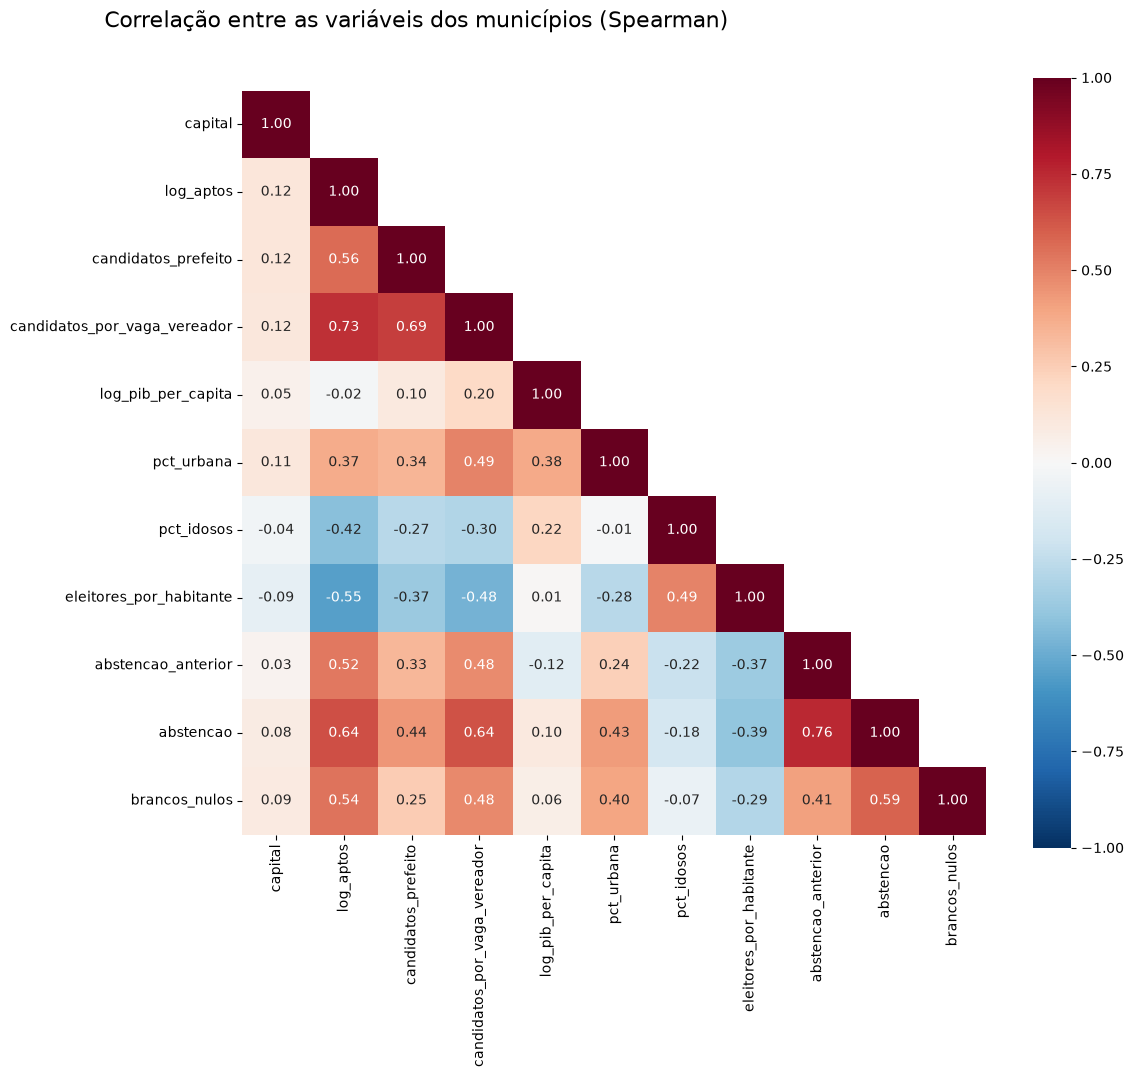

In [34]:
correlacao = base[FEATURES[1:] + ['abstencao']].join(
    mun_prefeito.set_index('codigo_tse')['brancos_nulos']).corr(method='spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True,
            mask=np.triu(np.ones_like(correlacao, dtype=bool), k=1))
titulo('Correlação entre as variáveis dos municípios (Spearman)')
salvar('Correlacao entre variaveis dos municipios')
plt.show()

📌 **Nota**
- 🔎 A variável mais ligada à abstenção é a **abstenção da eleição anterior** (**0,76**): municípios com muita abstenção em 2016 continuaram com muita abstenção em 2020.
- 🔎 Em seguida vêm o **tamanho do município** (`log_aptos`: **0,64**), a **concorrência para vereador** (**0,64**) e a **urbanização** (**0,43**). Os votos **brancos e nulos** andam junto com a abstenção (**0,59**).
- 🔎 **Eleitores por habitante** (**−0,39**) e **idosos** (**−0,18**) têm correlação negativa: são mais comuns nas cidades pequenas, onde a abstenção é menor (H12).
- ⚠️ Várias variáveis são correlacionadas entre si (ex.: tamanho e concorrência, **0,73**). Por isso, não dá para olhar uma de cada vez: o modelo da Fase 03 separa o efeito de cada uma.

#### Correlação entre prefeitos, vereadores e candidatos por partido (análise da versão original)

A versão original mostrou que partidos que elegem mais prefeitos também elegem mais vereadores e lançam mais candidatos (correlação acima de 0,9) e concluiu que *"quanto mais candidatos, mais eleitos"*.

In [35]:
partidos[['candidatos_prefeito', 'prefeitos_eleitos', 'candidatos_vereador', 'vereadores_eleitos',
          'sucesso_prefeito', 'sucesso_vereador']].corr(method='spearman').round(2)

,candidatos_prefeito,prefeitos_eleitos,candidatos_vereador,vereadores_eleitos,sucesso_prefeito,sucesso_vereador
candidatos_prefeito,1.000,0.970,0.980,0.970,0.910,0.920
prefeitos_eleitos,0.970,1.000,0.980,0.990,0.980,0.970
candidatos_vereador,0.980,0.980,1.000,0.990,0.930,0.950
vereadores_eleitos,0.970,0.990,0.990,1.000,0.960,0.980
sucesso_prefeito,0.910,0.980,0.930,0.960,1.000,0.970
sucesso_vereador,0.920,0.970,0.950,0.980,0.970,1.000


📌 **Nota**
- 🔎 A correlação continua altíssima (**0,99** entre prefeitos e vereadores eleitos), mas ela mostra principalmente o **tamanho** de cada partido: partidos grandes lançam mais candidatos **e** elegem mais.
- 🔎 O dado novo é que a **taxa de sucesso** também cresce com o tamanho (**0,98** entre prefeitos eleitos e sucesso para prefeito): os partidos grandes não só elegem mais, como elegem **uma parcela maior** dos seus candidatos.
- ⚠️ Correlação não é causa: a conclusão da v1 de que *"quanto mais candidatos você colocar, mais vai eleger"* não se sustenta. O PT lançou quase tantos candidatos a prefeito quanto o PSDB (**1.224** x **1.273**) e elegeu **179** prefeitos, contra **512** do PSDB (H3).

# FASE 03: MODELAGEM

**Pergunta 5:** *qual abstenção é esperada para um município, dado o seu perfil?*

Com essa estimativa, um órgão eleitoral ou um partido consegue identificar cidades onde **muito mais (ou muito menos) eleitores faltaram do que o esperado** e investigar o motivo (transporte, Covid, falta de interesse na disputa...).

> ⚠️ O modelo é treinado com a eleição de **2020** (durante a pandemia). Na Fase 04, testamos se ele também funciona **fora do tempo**, aplicando-o à eleição de **2024**.

## 1 - LEITURA DOS DADOS

In [36]:
X = base[FEATURES]
y = base['abstencao']
print(f'Municípios: {len(X):,} | Variáveis: {FEATURES}')

Municípios: 5,568 | Variáveis: ['uf', 'capital', 'log_aptos', 'candidatos_prefeito', 'candidatos_por_vaga_vereador', 'log_pib_per_capita', 'pct_urbana', 'pct_idosos', 'eleitores_por_habitante', 'abstencao_anterior']


## 2 - VALORES NULOS

In [37]:
X.isna().sum().to_frame('nulos').T

,uf,capital,log_aptos,candidatos_prefeito,candidatos_por_vaga_vereador,log_pib_per_capita,pct_urbana,pct_idosos,eleitores_por_habitante,abstencao_anterior
nulos,0,0,0,0,0,0,5,0,0,0


📌 **Nota**
- 🔎 `pct_urbana` está vazio em **5** municípios, criados depois do Censo de 2010.
- 🔎 `abstencao_anterior` está vazio em **1** município, sem eleição ordinária registrada em 2016.
- ✅ **Decisão:** manter esses municípios. O HistGradientBoosting trata o valor vazio sozinho, e para os outros modelos ele é preenchido pela **mediana** dentro do `Pipeline` (item 3).

## 3 - TRANSFORMAÇÃO DOS DADOS

| Variável | Transformação | Motivo |
|---|---|---|
| `uf` | **One-hot** (uma coluna 0/1 por estado) | Modelos só trabalham com números |
| Numéricas | **Preenchimento** dos nulos pela mediana + **padronização** (média 0, desvio 1), só para o modelo linear | A Regressão Ridge não aceita nulos e precisa das variáveis na mesma escala. O HistGradientBoosting lida com nulos e escalas sozinho; a Random Forest recebe só o preenchimento |

As transformações ficam **dentro de um `Pipeline`**, para que sejam aprendidas só com os dados de treino a cada etapa da validação cruzada.

In [38]:
NUMERICAS = [coluna for coluna in FEATURES if coluna != 'uf']

transformacao_linear = ColumnTransformer([
    ('uf', OneHotEncoder(handle_unknown='ignore'), ['uf']),
    ('numericas', Pipeline([('preencher', SimpleImputer(strategy='median')), ('padronizar', StandardScaler())]),
     NUMERICAS),
])
transformacao_arvore = ColumnTransformer([
    ('uf', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['uf']),
], remainder='passthrough')

# A Random Forest não aceita nulos: preenchimento pela mediana antes das árvores
transformacao_floresta = ColumnTransformer([
    ('uf', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['uf']),
    ('numericas', SimpleImputer(strategy='median'), NUMERICAS),
])

## 4 - PRÉ-PROCESSAMENTO

### 4.1. Separação em treino e teste

In [39]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEMENTE)
print(f'Treino: {len(X_treino):,} municípios | Teste: {len(X_teste):,} municípios')

Treino: 4,454 municípios | Teste: 1,114 municípios


📌 **Nota**
- 🔎 **80%** dos municípios para treinar e comparar os modelos (com validação cruzada) e **20%** guardados para o **teste final**, usado uma única vez na Fase 04.

### 4.2. Balanceamento

🚫 **Não se aplica.** O alvo é uma **taxa contínua** (regressão), não uma classe. A distribuição da abstenção (item 2.7) é próxima de uma curva normal, sem grupos raros que precisem ser reforçados.

### 4.3. Seleção de variáveis

Nem toda variável ajuda o modelo da mesma forma. Esta etapa mede a relevância de cada uma usando dois métodos diferentes, que olham o problema por ângulos distintos:

| Método | Como funciona | Em palavras simples |
|---|---|---|
| **Random Forest** | treina várias árvores de decisão e mede o quanto cada variável ajuda a reduzir o erro da previsão | "quais perguntas o modelo mais usou para decidir" |
| **Informação Mútua** | mede o quanto conhecer a variável reduz a incerteza sobre o alvo | "quanto essa variável, sozinha, conta sobre a abstenção" |

Como o alvo é uma **taxa contínua**, usamos as versões de **regressão**: `RandomForestRegressor` e `mutual_info_regression`.

> Um cuidado técnico: os dois métodos só aceitam números sem vazios. Por isso usamos a **matriz transformada** (o estado vira colunas 0/1 e os vazios são preenchidos pela mediana, item 3). O pré-processador é ajustado **só no treino**, para que nenhuma informação do teste entre na seleção. Não há balanceamento a reaplicar: o alvo é contínuo (item 4.2).

treino transformado .... (4454, 35)


abstencao_anterior             0.575
candidatos_por_vaga_vereador   0.109
log_aptos                      0.068
log_pib_per_capita             0.067
pct_urbana                     0.049
pct_idosos                     0.026
eleitores_por_habitante        0.026
uf_PI                          0.012
candidatos_prefeito            0.011
uf_MG                          0.009
uf_PB                          0.007
uf_CE                          0.005
uf_TO                          0.004
uf_RN                          0.004
uf_GO                          0.003
uf_BA                          0.003
uf_AL                          0.003
uf_RS                          0.003
uf_RO                          0.002
uf_SP                          0.002


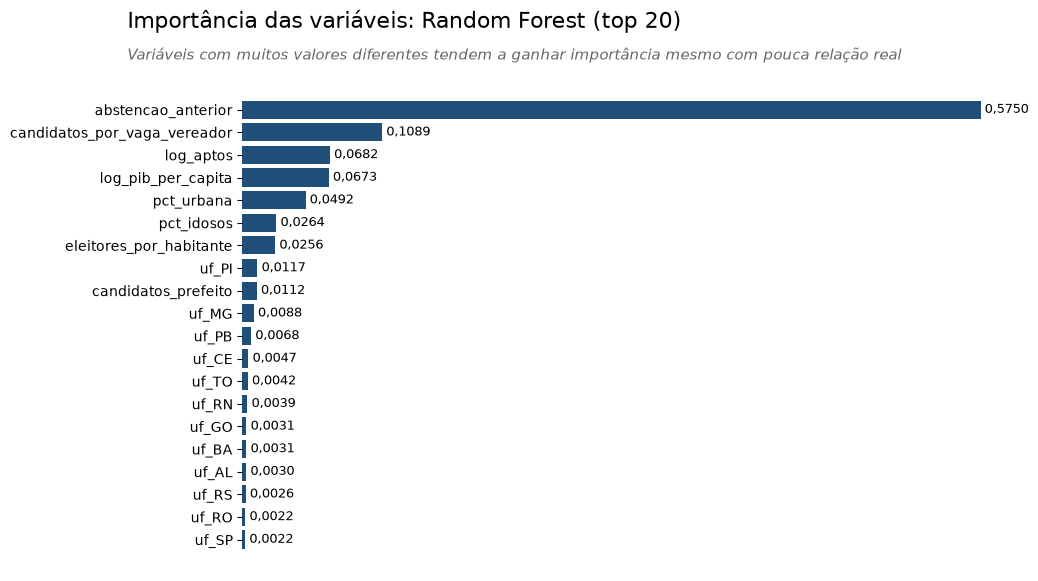

In [40]:
# Transformando o treino em números (ajuste só no treino)
prep_sel = clone(transformacao_floresta)
X_treino_t = pd.DataFrame(prep_sel.fit_transform(X_treino), index=X_treino.index,
                          columns=[nome.split('__')[-1] for nome in prep_sel.get_feature_names_out()])
print(f'treino transformado .... {X_treino_t.shape}')

# Random Forest - classificação das melhores variáveis
importances = importancia_random_forest(X_treino_t, y_treino, tipo='regressao', semente=SEMENTE)
print(importances.head(20).round(4).to_string())

plot_barras_h(importances.head(20), 'Importância das variáveis: Random Forest (top 20)', 'Importancia RF (selecao)',
              subtitulo='Variáveis com muitos valores diferentes tendem a ganhar importância mesmo com pouca relação real',
              formato=lambda v: f'{v:.4f}'.replace('.', ','))

informação mútua calculada em 5s

🎯 RANKING DE FEATURES POR MUTUAL INFORMATION (top 20 de 35):
                         feature  score
0             abstencao_anterior  0.483
1                      log_aptos  0.290
2   candidatos_por_vaga_vereador  0.268
3            candidatos_prefeito  0.145
4                     pct_urbana  0.120
5        eleitores_por_habitante  0.118
6                     pct_idosos  0.060
7                          uf_SP  0.043
8             log_pib_per_capita  0.038
9                          uf_RS  0.032
10                         uf_PI  0.022
11                         uf_RN  0.019
12                         uf_PB  0.018
13                         uf_BA  0.018
14                         uf_MT  0.013
15                         uf_TO  0.011
16                         uf_RO  0.010
17                         uf_CE  0.010
18                         uf_MA  0.009
19                         uf_PE  0.007

colunas com informação mútua igual a zero: 0 de 35

🏆 TOP 5 FEAT

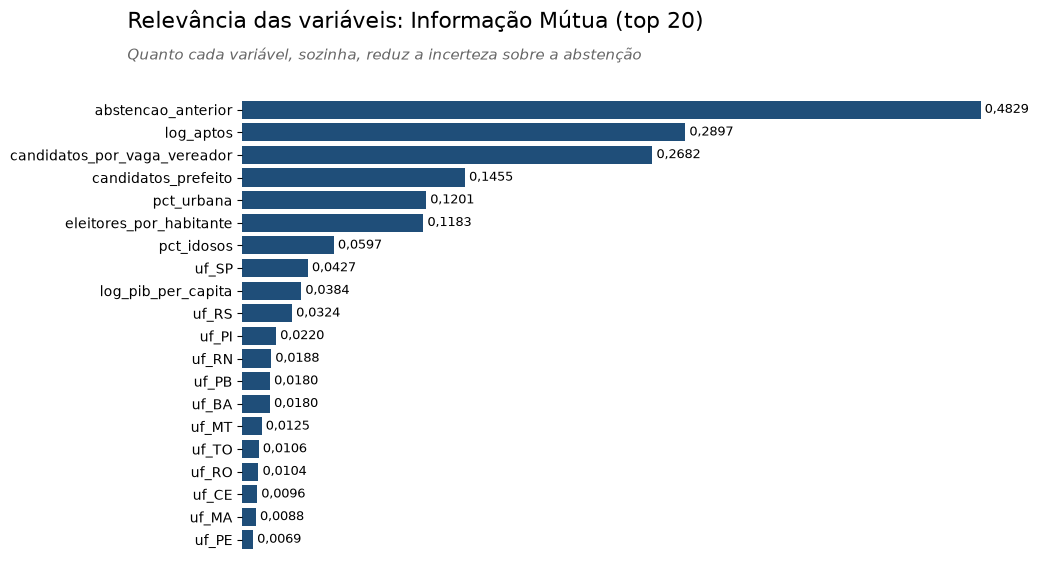

In [41]:
# Informação Mútua - ranking de todas as colunas e seleção das 5 melhores
t0 = time.time()
df_scores, selector = selecao_features(X_treino_t, y_treino, k=5, tipo='regressao', semente=SEMENTE)
print(f'informação mútua calculada em {time.time() - t0:.0f}s\n')

print(f'🎯 RANKING DE FEATURES POR MUTUAL INFORMATION (top 20 de {X_treino_t.shape[1]}):')
print('=' * 50)
print(df_scores.head(20).round(4).to_string())
print(f"\ncolunas com informação mútua igual a zero: {(df_scores['score'] == 0).sum()} de {len(df_scores)}")

print('\n🏆 TOP 5 FEATURES SELECIONADAS:')
print('=' * 50)
top_5_features = df_scores.head(5)['feature'].tolist()
for i, (feature, score) in enumerate(df_scores.head(5).itertuples(index=False), 1):
    print(f'{i}. {feature}: {score:.6f}')

X_treino_selecionado = selector.transform(X_treino_t)
print(f'\n📊 Shape original: {X_treino_t.shape}')
print(f'📊 Shape após seleção: {X_treino_selecionado.shape}')
print(f'📊 Features selecionadas: {top_5_features}')

plot_barras_h(df_scores.head(20).set_index('feature')['score'], 'Relevância das variáveis: Informação Mútua (top 20)',
              'Informacao mutua', subtitulo='Quanto cada variável, sozinha, reduz a incerteza sobre a abstenção',
              formato=lambda v: f'{v:.4f}'.replace('.', ','))

In [42]:
# Comparação dos dois rankings
comparacao_selecao = pd.DataFrame({
    'posição RF': importances.rank(ascending=False).astype(int),
    'posição Informação Mútua': df_scores.set_index('feature')['score'].rank(ascending=False, method='first').astype(int),
}).sort_values('posição RF')
comparacao_selecao.head(10)

,posição RF,posição Informação Mútua
abstencao_anterior,1,1
candidatos_por_vaga_vereador,2,3
log_aptos,3,2
log_pib_per_capita,4,9
pct_urbana,5,5
pct_idosos,6,7
eleitores_por_habitante,7,6
uf_PI,8,11
candidatos_prefeito,9,4
uf_MG,10,27


📌 **Nota**
- 🔎 Os dois métodos concordam no principal: a **abstenção da eleição anterior** é, de longe, a variável mais relevante (Random Forest **0,575**; Informação Mútua **0,483**), seguida do **tamanho do município** e da **concorrência para vereador**.
- 🔎 As diferenças são esperadas: o Random Forest coloca o **PIB per capita** em 4º lugar, mas a Informação Mútua o coloca em 9º. Variáveis com muitos valores diferentes (como o PIB) tendem a ganhar importância no Random Forest mesmo com pouca relação real com o alvo, o mesmo alerta do gráfico.
- 🔎 Cada **estado** vira uma coluna 0/1 e aparece com importância pequena **sozinho** (ex.: `uf_PI`, `uf_SP`). Somados, porém, os estados pesam bastante: a importância por permutação da Fase 04 mede `uf` como um bloco e o coloca em 3º lugar.
- 🔎 Nenhuma coluna tem informação mútua igual a zero: todas carregam alguma informação sobre a abstenção.
- ✅ **Decisão:** manter as **10 variáveis**. As 5 mais bem colocadas na Informação Mútua (`abstencao_anterior`, `log_aptos`, `candidatos_por_vaga_vereador`, `candidatos_prefeito` e `pct_urbana`) estão entre as mais fortes dos dois métodos, e a confirmação abaixo mostra que o modelo com todas as variáveis tem o menor erro.

#### Confirmação: o modelo melhora com cada grupo de variáveis?

Os dois métodos acima olham cada coluna isoladamente. Como confirmação, comparamos o mesmo modelo (HistGradientBoosting) com **4 conjuntos de variáveis**, na validação cruzada do treino, para saber se cada grupo novo (IBGE, histórico e Covid) realmente reduz o erro.

In [43]:
validacao = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
conjuntos = {
    'Só dados da eleição (5)': FEATURES_ELEICAO,
    '+ IBGE (9)': FEATURES_ELEICAO + FEATURES_IBGE,
    '+ IBGE + abstenção anterior (10)': FEATURES,
    '+ Covid (13)': FEATURES + FEATURES_COVID,
}
selecao = {}
for nome, colunas in conjuntos.items():
    modelo = Pipeline([('transformacao', transformacao_arvore),
                       ('modelo', HistGradientBoostingRegressor(random_state=SEMENTE))])
    dados_treino = base.loc[X_treino.index, colunas]  # inclui as colunas de Covid, que não estão em X
    cv = cross_validate(modelo, dados_treino, y_treino, cv=validacao, scoring=['neg_mean_absolute_error', 'r2'])
    selecao[nome] = {'MAE (p.p.)': -cv['test_neg_mean_absolute_error'].mean() * 100, 'R²': cv['test_r2'].mean()}
pd.DataFrame(selecao).T.round(3)

,MAE (p.p.),R²
Só dados da eleição (5),2.774,0.663
+ IBGE (9),2.615,0.695
+ IBGE + abstenção anterior (10),2.021,0.817
+ Covid (13),2.027,0.816


📌 **Nota**
- 🔎 Os dados do **IBGE** reduzem o erro de **2,77** para **2,62 p.p.** (R² de 0,66 para **0,70**).
- 🔎 A **abstenção da eleição anterior** dá o maior salto: o erro cai para **2,02 p.p.** e o R² sobe para **0,82**. Ela resume tudo o que é **estável** em cada município (distância das seções, perfil do eleitorado, cadastro), que nenhuma outra variável captura.
- 🔎 Os dados de **Covid** não ajudam: o erro fica em **2,03 p.p.** (confirma a H13).
- ✅ **Decisão:** usar as **10 variáveis**, sem a Covid. Todas são conhecidas antes da eleição, inclusive a abstenção de 4 anos antes.

## 5 - TREINAMENTO DOS MODELOS

| Modelo | Ideia | Por que testar |
|---|---|---|
| **Média (referência)** | Prevê sempre a abstenção média | Qualquer modelo útil precisa ser **melhor que isso** |
| **Regressão Ridge** | Reta (com penalização) sobre as variáveis | Simples e fácil de explicar |
| **Random Forest** | Média de centenas de árvores de decisão | Captura relações não lineares |
| **HistGradientBoosting** | Árvores treinadas em sequência, cada uma corrigindo o erro da anterior | Costuma ser o mais preciso em tabelas |

Todos são avaliados com **validação cruzada de 5 partes** no treino. A métrica principal é o **erro absoluto médio (MAE)** em **pontos percentuais (p.p.)**: um MAE de 3 p.p. significa que, se a abstenção real foi 20%, o modelo costuma prever entre 17% e 23%.

In [44]:
modelos = {
    'Média (referência)': DummyRegressor(),
    'Regressão Ridge': Pipeline([('transformacao', transformacao_linear), ('modelo', Ridge())]),
    'Random Forest': Pipeline([('transformacao', transformacao_floresta),
                               ('modelo', RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                                                random_state=SEMENTE, n_jobs=-1))]),
    'HistGradientBoosting': Pipeline([('transformacao', transformacao_arvore),
                                      ('modelo', HistGradientBoostingRegressor(random_state=SEMENTE))]),
}

metricas = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

resultados = {}
for nome, modelo in modelos.items():
    inicio = time.time()
    cv = cross_validate(modelo, X_treino, y_treino, cv=validacao, scoring=metricas)
    resultados[nome] = {'MAE (p.p.)': -cv['test_MAE'].mean() * 100, 'RMSE (p.p.)': -cv['test_RMSE'].mean() * 100,
                        'R²': cv['test_R2'].mean(), 'Tempo (s)': time.time() - inicio}

## 6 - COMPARAÇÃO DOS MODELOS

,MAE (p.p.),RMSE (p.p.),R²,Tempo (s)
HistGradientBoosting,2.02,2.61,0.82,24.92
Random Forest,2.17,2.81,0.79,30.82
Regressão Ridge,2.30,2.92,0.77,0.52
Média (referência),5.04,6.12,-0.00,0.08


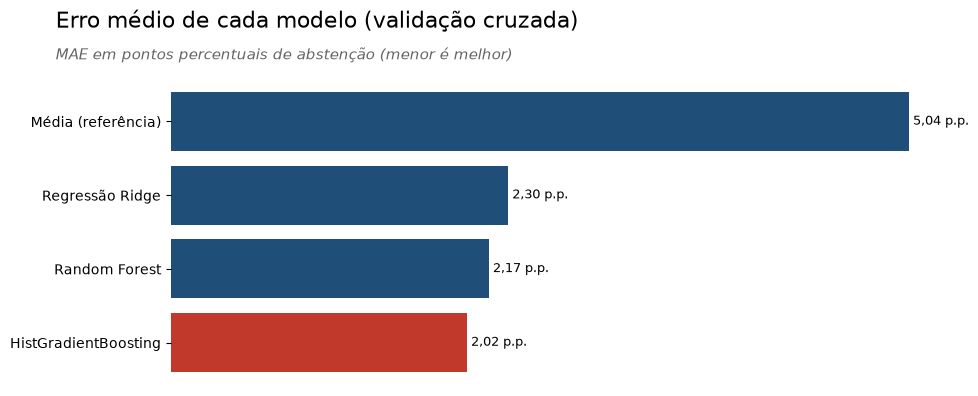

In [45]:
comparacao = pd.DataFrame(resultados).T.sort_values('MAE (p.p.)')
display(comparacao.style.format('{:.2f}').highlight_min(subset=['MAE (p.p.)', 'RMSE (p.p.)'], color='#C8E6C9'))

plot_barras_h(comparacao['MAE (p.p.)'].sort_values(ascending=False), 'Erro médio de cada modelo (validação cruzada)',
              'Comparacao de modelos', subtitulo='MAE em pontos percentuais de abstenção (menor é melhor)',
              formato=pp, destaque=[comparacao.index[0]])

📌 **Nota**
- 🔎 Prevendo sempre a média, o erro é de **5,04 p.p.**. Todos os modelos reduzem esse erro **para menos da metade**.
- 🔎 O **HistGradientBoosting** teve o menor erro (**2,02 p.p.**, R² de **0,82**), seguido da Random Forest (2,17) e da Regressão Ridge (2,30).
- ✅ **Decisão:** seguir com o **HistGradientBoosting** para o ajuste fino. A Regressão Ridge, bem mais simples, ficou 0,28 p.p. atrás: a maior parte do padrão é **simples** (abstenção anterior + tamanho + estado).

## 7 - AJUSTE FINO DOS HIPERPARÂMETROS

### 7.1. Busca aleatória

Testamos 30 combinações de hiperparâmetros do **HistGradientBoosting** (taxa de aprendizado, profundidade, tamanho mínimo das folhas e regularização), escolhendo a de **menor MAE** na validação cruzada.

In [46]:
espaco_busca = {
    'modelo__learning_rate': [0.02, 0.05, 0.1, 0.2],
    'modelo__max_iter': [100, 200, 400],
    'modelo__max_leaf_nodes': [7, 15, 31],
    'modelo__min_samples_leaf': [10, 20, 40, 80],
    'modelo__l2_regularization': [0, 0.1, 1, 10],
}
busca = RandomizedSearchCV(modelos['HistGradientBoosting'], espaco_busca, n_iter=30, cv=validacao,
                           scoring='neg_mean_absolute_error', random_state=SEMENTE, n_jobs=-1)
busca.fit(X_treino, y_treino)

print('Melhores hiperparâmetros:', {k.replace('modelo__', ''): v for k, v in busca.best_params_.items()})
print(f"MAE na validação cruzada: {-busca.best_score_ * 100:.2f} p.p. "
      f"(antes do ajuste: {comparacao.loc['HistGradientBoosting', 'MAE (p.p.)']:.2f} p.p.)")

Melhores hiperparâmetros: {'min_samples_leaf': 10, 'max_leaf_nodes': 31, 'max_iter': 400, 'learning_rate': 0.02, 'l2_regularization': 0.1}
MAE na validação cruzada: 2.00 p.p. (antes do ajuste: 2.02 p.p.)


📌 **Nota**
- 🔎 O ajuste fino reduziu o erro de **2,02 p.p.** para **2,00 p.p.**. O ganho é pequeno: os hiperparâmetros padrão já eram bons.
- 🔎 A melhor combinação usa uma **taxa de aprendizado baixa** (0,02) com **mais árvores** (400): o modelo aprende devagar, o que costuma generalizar melhor.

### 7.2. Robustez do modelo ajustado

Conferimos se o erro é estável entre as 5 partes da validação cruzada (um modelo que acerta muito em uma parte e erra muito em outra não é confiável).

In [47]:
cv_final = cross_validate(busca.best_estimator_, X_treino, y_treino, cv=validacao, scoring=metricas)
print('MAE por parte (p.p.):', np.round(-cv_final['test_MAE'] * 100, 2))
print('R² por parte:', np.round(cv_final['test_R2'], 3))

MAE por parte (p.p.): [1.96 2.04 1.98 2.04 2.  ]
R² por parte: [0.815 0.827 0.836 0.815 0.806]


📌 **Nota**
- 🔎 O erro ficou entre **1,96 e 2,04 p.p.** e o R² entre **0,81 e 0,84** nas 5 partes: o desempenho é **estável**, sem depender de uma divisão específica dos dados.

### 7.3. Modelo final

In [48]:
modelo_final = busca.best_estimator_
modelo_final

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformacao', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['uf','capital','log_aptos',...,'pct_idosos','eleitores_por_habitante', 'abstencao_anterior']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('uf', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset o

📌 **Nota**
- ✅ **Decisão:** o modelo final é o **HistGradientBoosting ajustado**, já treinado com todo o conjunto de treino pela busca (`refit`).

## 8 - INCERTEZA E CALIBRAÇÃO DAS PREVISÕES

### 8.1. Limiar de decisão

🚫 **Não se aplica.** O limiar serve para transformar uma **probabilidade** em uma **classe** (ex.: "fraude" ou "não fraude"). Aqui o modelo já devolve a própria **taxa de abstenção**. No lugar do limiar, medimos **o quanto a previsão pode errar**.

### 8.2. Faixa de erro esperada

Usamos as previsões **fora da amostra** da validação cruzada no treino (cada município é previsto por um modelo que não o viu) para medir os erros típicos. A faixa entre o **10º e o 90º percentil** dos erros contém **80%** dos casos.

In [49]:
previsto_fora_amostra = cross_val_predict(modelo_final, X_treino, y_treino, cv=validacao)
erros_treino = y_treino - previsto_fora_amostra
erro_p10, erro_p90 = np.quantile(erros_treino, [0.10, 0.90])
print(f'80% dos municípios ficam entre {erro_p10 * 100:+.1f} p.p. e {erro_p90 * 100:+.1f} p.p. da previsão')

80% dos municípios ficam entre -3.2 p.p. e +3.2 p.p. da previsão


### 8.3. Faixa de erro aplicada no teste

In [50]:
previsto_teste = modelo_final.predict(X_teste)
dentro = ((y_teste >= previsto_teste + erro_p10) & (y_teste <= previsto_teste + erro_p90)).mean()
print(f'Municípios do teste dentro da faixa: {dentro:.1%} (esperado: 80%)')

Municípios do teste dentro da faixa: 79.6% (esperado: 80%)

📌 **Nota**
- 🔎 Em 80% dos municípios, a abstenção real fica a até **3,2 p.p.** da previsão, para cima ou para baixo. Exemplo: se o modelo prevê 20%, o esperado é algo entre **16,8% e 23,2%**.
- 🔎 No teste, **79,6%** dos municípios ficaram dentro dessa faixa, praticamente os 80% esperados: a faixa é **confiável** e é a que o app mostra.

### 8.4. Calibração

Um modelo **calibrado** acerta na média em todas as faixas: quando prevê 25%, a abstenção real dos municípios deve ficar perto de 25%. Separamos os municípios do teste em 10 grupos pela previsão e comparamos a média prevista com a real.

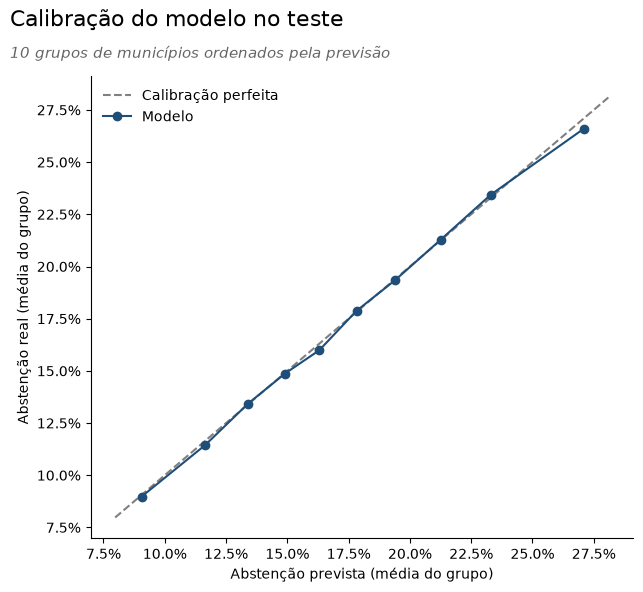

In [51]:
calibracao = (pd.DataFrame({'previsto': previsto_teste, 'real': y_teste.values})
              .assign(grupo=lambda t: pd.qcut(t['previsto'], 10, labels=False))
              .groupby('grupo').mean())

plt.figure(figsize=(7, 6))
limites = [calibracao.min().min() - 0.01, calibracao.max().max() + 0.01]
plt.plot(limites, limites, color='gray', ls='--', label='Calibração perfeita')
plt.plot(calibracao['previsto'], calibracao['real'], marker='o', color=COR_PRINCIPAL, label='Modelo')
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xlabel('Abstenção prevista (média do grupo)')
plt.ylabel('Abstenção real (média do grupo)')
plt.legend(frameon=False)
sns.despine()
titulo('Calibração do modelo no teste', '10 grupos de municípios ordenados pela previsão')
salvar('Calibracao do modelo')
plt.show()

📌 **Nota**
- 🔎 Os pontos ficam colados à linha tracejada em todas as faixas, de cerca de **9%** a **27%** de abstenção: o modelo **não tem viés** sistemático, nem para cidades de abstenção baixa nem para as de abstenção alta.

# FASE 04: AVALIAÇÃO

## 1 - AVALIAÇÃO DO MODELO NO TESTE

In [52]:
referencia_teste = np.full(len(y_teste), y_treino.mean())
avaliacao = pd.DataFrame({
    'MAE (p.p.)': [mean_absolute_error(y_teste, referencia_teste) * 100, mean_absolute_error(y_teste, previsto_teste) * 100],
    'RMSE (p.p.)': [root_mean_squared_error(y_teste, referencia_teste) * 100,
                    root_mean_squared_error(y_teste, previsto_teste) * 100],
    'R²': [r2_score(y_teste, referencia_teste), r2_score(y_teste, previsto_teste)],
}, index=['Média (referência)', 'Modelo final'])
avaliacao.round(3)

,MAE (p.p.),RMSE (p.p.),R²
Média (referência),4.892,5.907,-0.000
Modelo final,2.018,2.650,0.799


📌 **Nota**
- 🔎 No teste (1.114 municípios que o modelo nunca viu), o erro médio foi de **2,02 p.p.**, contra **4,89 p.p.** de quem prevê sempre a média: **59% menos erro**.
- 🔎 O **R² de 0,80** significa que o modelo explica **80%** das diferenças de abstenção entre os municípios usando 10 informações conhecidas antes da eleição. O resultado é praticamente igual ao da validação cruzada (2,00 p.p.): **não houve sobreajuste**.
- ⚠️ Os outros **20%** dependem de fatores que não estão na base, como casos de Covid, transporte no dia da eleição e o interesse pela disputa local.

## 2 - PREVISTO × OBSERVADO

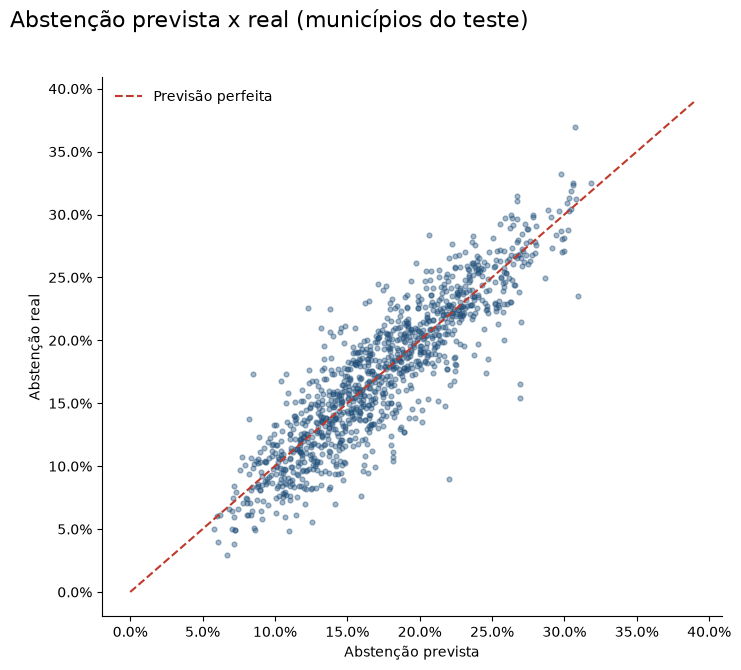

In [53]:
plt.figure(figsize=(8, 7))
plt.scatter(previsto_teste, y_teste, s=12, alpha=0.4, color=COR_PRINCIPAL)
limites = [0, max(previsto_teste.max(), y_teste.max()) + 0.02]
plt.plot(limites, limites, color=COR_DESTAQUE, ls='--', label='Previsão perfeita')
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xlabel('Abstenção prevista')
plt.ylabel('Abstenção real')
plt.legend(frameon=False)
sns.despine()
titulo('Abstenção prevista x real (municípios do teste)')
salvar('Previsto x observado')
plt.show()

#### Municípios que mais fugiram do padrão

Para listar **todos** os municípios (e não só os do teste) sem que o modelo "conheça a resposta", usamos previsões **fora da amostra**: cada município é previsto por um modelo treinado sem ele.

In [54]:
base['abstencao_esperada'] = cross_val_predict(modelo_final, X, y, cv=validacao)
base['diferenca_pp'] = (base['abstencao'] - base['abstencao_esperada']) * 100
colunas = ['municipio', 'uf', 'aptos', 'abstencao', 'abstencao_esperada', 'diferenca_pp']

print('Abstenção MUITO ACIMA do esperado:')
display(base.nlargest(8, 'diferenca_pp')[colunas])
print('Abstenção MUITO ABAIXO do esperado:')
display(base.nsmallest(8, 'diferenca_pp')[colunas])

Abstenção MUITO ACIMA do esperado:


,municipio,uf,aptos,abstencao,abstencao_esperada,diferenca_pp
codigo_tse,,,,,,
76252,IVATUBA,PR,2754,0.241,0.130,11.154
96075,SERRANÓPOLIS,GO,5882,0.226,0.123,10.266
94331,JATAÍ,GO,68256,0.317,0.219,9.749
46710,ITAPEVA,MG,7726,0.235,0.142,9.321
90972,JARAGUARI,MS,5262,0.221,0.132,8.934
88986,ACEGUÁ,RS,3757,0.213,0.124,8.923
671,CAMPO NOVO DE RONDÔNIA,RO,7773,0.294,0.205,8.862
12637,FLORESTA DO PIAUÍ,PI,2544,0.173,0.085,8.836


Abstenção MUITO ABAIXO do esperado:


,municipio,uf,aptos,abstencao,abstencao_esperada,diferenca_pp
codigo_tse,,,,,,
49352,FRONTEIRA DOS VALES,MG,3745,0.089,0.220,-13.072
15881,CROATÁ,CE,13706,0.154,0.269,-11.468
23060,XEXÉU,PE,10238,0.165,0.269,-10.451
7218,AXIXÁ,MA,9019,0.080,0.178,-9.784
58122,QUEIMADOS,RJ,87662,0.147,0.243,-9.530
7994,ICATU,MA,19438,0.092,0.184,-9.262
72397,VIRADOURO,SP,12576,0.172,0.263,-9.162
23256,BARRA DE GUABIRABA,PE,9466,0.087,0.176,-8.945


📌 **Nota**
- 🔎 Como o modelo agora conhece a abstenção de 2016, "fora do padrão" significa **mudança em relação ao histórico** da própria cidade.
- 🔎 **Acima do esperado:** em **Ivatuba (PR)**, a abstenção quase dobrou, de **12,9%** (2016) para **24,1%**. Em **Jataí (GO)**, cidade média, foi de 15,7% para **31,7%**, contra 22,0% esperados.
- 🔎 **Abaixo do esperado:** em **Fronteira dos Vales (MG)**, só **8,9%** faltaram, contra **22,0%** esperados (19,4% em 2016). Em **Queimados (RJ)**, na Baixada Fluminense, foram **14,7%**, contra 24,2% esperados.
- 💡 Para um órgão eleitoral, essa lista é um **ponto de partida para investigar**: surto de Covid na época da eleição, revisão do cadastro de eleitores, problemas de transporte ou uma disputa local muito acirrada, que leva mais gente às urnas.

## 3 - VARIÁVEIS QUE MAIS INFLUENCIAM

Usamos a **importância por permutação**: embaralhamos uma variável de cada vez no teste e medimos **quanto o erro piora**. Quanto mais o erro piora, mais o modelo depende daquela variável.

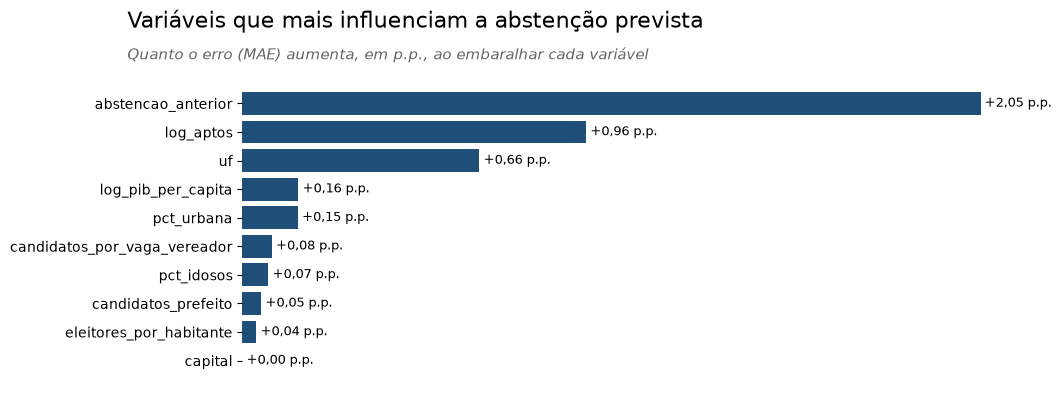

In [55]:
importancia = permutation_importance(modelo_final, X_teste, y_teste, scoring='neg_mean_absolute_error',
                                     n_repeats=20, random_state=SEMENTE, n_jobs=-1)
importancia = pd.Series(importancia.importances_mean * 100, index=X_teste.columns)

plot_barras_h(importancia, 'Variáveis que mais influenciam a abstenção prevista', 'Importancia das variaveis',
              subtitulo='Quanto o erro (MAE) aumenta, em p.p., ao embaralhar cada variável',
              formato=lambda v: pp(v, sinal=True))

In [56]:
# Efeito do tamanho do município: mantém todo o resto igual e varia só o número de eleitores
perfil = X_teste.copy()
efeito_tamanho = {}
for eleitores in [5_000, 20_000, 100_000, 500_000]:
    perfil['log_aptos'] = np.log10(eleitores)
    efeito_tamanho[f'{eleitores:,}'.replace(',', '.')] = modelo_final.predict(perfil).mean()
pd.Series(efeito_tamanho).map(lambda v: pct(v, 1)).to_frame('abstenção média prevista')

,abstenção média prevista
5.000,"16,1%"
20.000,"19,2%"
100.000,"19,9%"
500.000,"20,3%"


📌 **Nota**
- 🔎 A **abstenção da eleição anterior** é, de longe, a variável mais importante: embaralhá-la aumenta o erro em **2,05 p.p.**. Em seguida vêm o **tamanho do município** (**0,96 p.p.**) e o **estado** (**0,66 p.p.**).
- 🔎 PIB per capita e urbanização ajudam pouco (**0,16** e **0,15 p.p.**), porque boa parte da informação delas já está no tamanho e na abstenção anterior. `capital` não acrescenta nada.
- 🔎 Mantendo todo o resto igual, a abstenção prevista sobe de **16,1%** para um município com 5 mil eleitores para **19,2%** com 20 mil e **20,3%** com 500 mil. O efeito é forte nas cidades pequenas e **se estabiliza** acima de 100 mil eleitores.

## 4 - TESTE FORA DO TEMPO: A ELEIÇÃO DE 2024

O teste da seção 1 usa municípios de **2020** que o modelo não viu. Mas a pergunta mais exigente é: **o modelo treinado em 2020 funciona em outra eleição?**

Aplicamos o modelo final, sem nenhum novo treino, aos municípios de **2024**, com as variáveis daquele ano (candidatos, eleitores e população de 2024, e a abstenção de **2020** como "eleição anterior").

,MAE (p.p.),Viés médio (p.p.),R²,Ordenação (Spearman)
Teste 2020,2.018,0.092,0.799,0.888
2024 (modelo de 2020),3.419,2.783,0.396,0.855
2024 descontando o viés médio,2.500,0.000,0.662,0.855


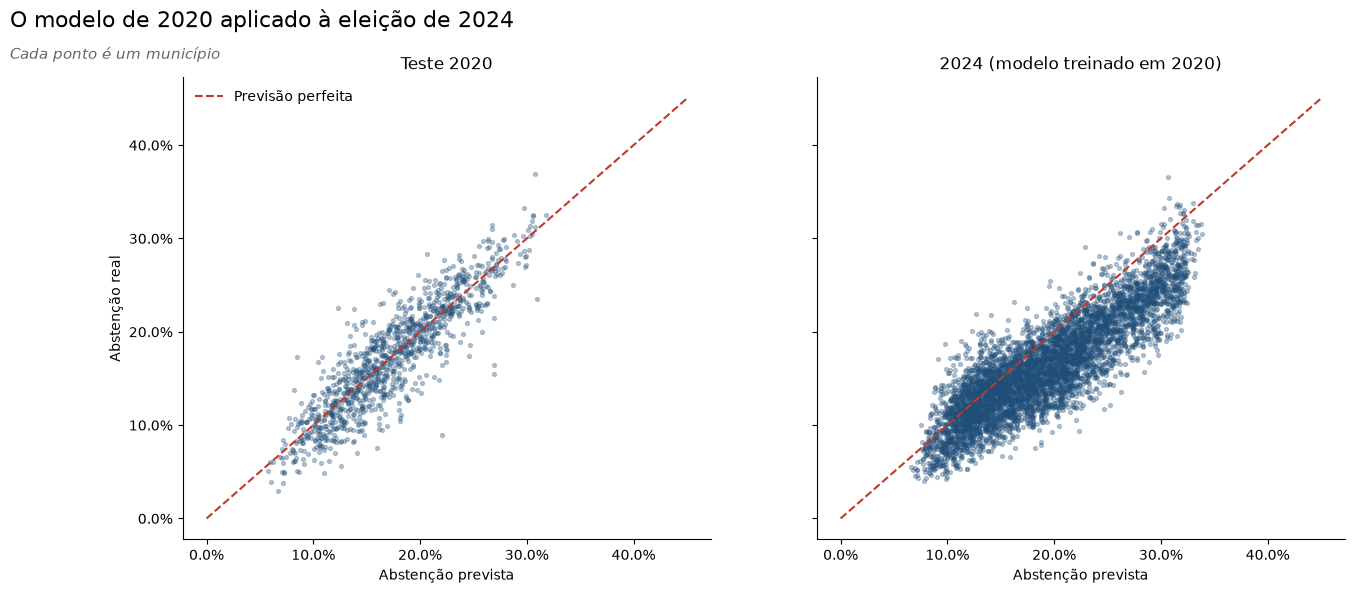

In [57]:
base_2024 = base_modelo(painel, 2024)
previsto_2024 = modelo_final.predict(base_2024[FEATURES])
real_2024 = base_2024['abstencao']
vies_2024 = (previsto_2024 - real_2024).mean()

fora_do_tempo = pd.DataFrame({
    'MAE (p.p.)': [mean_absolute_error(y_teste, previsto_teste) * 100, mean_absolute_error(real_2024, previsto_2024) * 100,
                   mean_absolute_error(real_2024, previsto_2024 - vies_2024) * 100],
    'Viés médio (p.p.)': [(previsto_teste - y_teste).mean() * 100, vies_2024 * 100, 0],
    'R²': [r2_score(y_teste, previsto_teste), r2_score(real_2024, previsto_2024),
           r2_score(real_2024, previsto_2024 - vies_2024)],
    'Ordenação (Spearman)': [spearmanr(previsto_teste, y_teste)[0], spearmanr(previsto_2024, real_2024)[0],
                             spearmanr(previsto_2024, real_2024)[0]],
}, index=['Teste 2020', '2024 (modelo de 2020)', '2024 descontando o viés médio'])
display(fora_do_tempo.round(3))

fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, previsto, real, nome in [(axs[0], previsto_teste, y_teste, 'Teste 2020'),
                                 (axs[1], previsto_2024, real_2024, '2024 (modelo treinado em 2020)')]:
    ax.scatter(previsto, real, s=8, alpha=0.3, color=COR_PRINCIPAL)
    ax.plot([0, 0.45], [0, 0.45], color=COR_DESTAQUE, ls='--', label='Previsão perfeita')
    ax.set_title(nome)
    ax.set_xlabel('Abstenção prevista')
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axs[0].set_ylabel('Abstenção real')
axs[0].legend(frameon=False)
sns.despine()
titulo('O modelo de 2020 aplicado à eleição de 2024', 'Cada ponto é um município')
salvar('Teste fora do tempo 2024')
plt.show()

📌 **Nota**
- 🔎 Em 2024, o modelo de 2020 **continua ordenando bem** os municípios (Spearman de **0,86**, perto do **0,89** do teste de 2020): ele sabe **quais cidades** terão mais ou menos abstenção.
- ⚠️ Mas ele **superestima o nível**: em média, prevê **2,8 p.p. a mais** do que a abstenção real, e o erro sobe para **3,42 p.p.** (R² de **0,40**). O motivo é que o modelo aprendeu a relação de 2016 → 2020, quando a abstenção **subiu** com a pandemia. De 2020 para 2024 ela **caiu**.
- 🔎 Descontando só esse viés médio, o erro cai para **2,50 p.p.** e o R² volta a **0,66**.
- 💡 **Lição para o negócio:** o modelo serve bem para **comparar municípios** em uma eleição (onde investigar, onde reforçar a comunicação). Para prever o **nível nacional** de uma eleição futura, é preciso informar o contexto (pandemia, interesse na disputa) ou treinar com várias eleições.

### 4.2. Modelo multi-eleição: separar o município do contexto nacional

O modelo de 2020 errou o **nível** de 2024 porque aprendeu a subida da pandemia. A solução é ensinar o modelo a prever só o que é **próprio de cada município** e tratar o nível nacional como um **cenário**:

| Passo | Como |
|---|---|
| **Alvo** | `abstencao_relativa` = abstenção do município − abstenção nacional daquela eleição |
| **Histórico** | `abstencao_anterior_relativa` = abstenção anterior do município − nível nacional da eleição anterior (2012 para 2016) |
| **Treino** | Eleições de **2016 e 2020** juntas (11 mil linhas): o modelo vê uma eleição "normal" e uma de pandemia |
| **Teste** | **2024**, nunca vista no treino |
| **Previsão** | previsão relativa + nível nacional do ano |

> 💡 Na prática, o nível nacional de uma eleição futura é desconhecido. Ele pode vir de um cenário (ex.: "igual a 2024") ou de pesquisas. No teste, usamos o nível real de 2024 para medir só o erro **entre municípios**, que é o que o modelo controla.

Treino: 11,135 linhas (2016 + 2020) | Teste: 5,567 municípios (2024)


,MAE (p.p.),Viés médio (p.p.),R²,Ordenação (Spearman)
Modelo de 2020,3.419,2.783,0.396,0.855
Modelo multi-eleição (2016 + 2020),2.267,-0.542,0.726,0.854


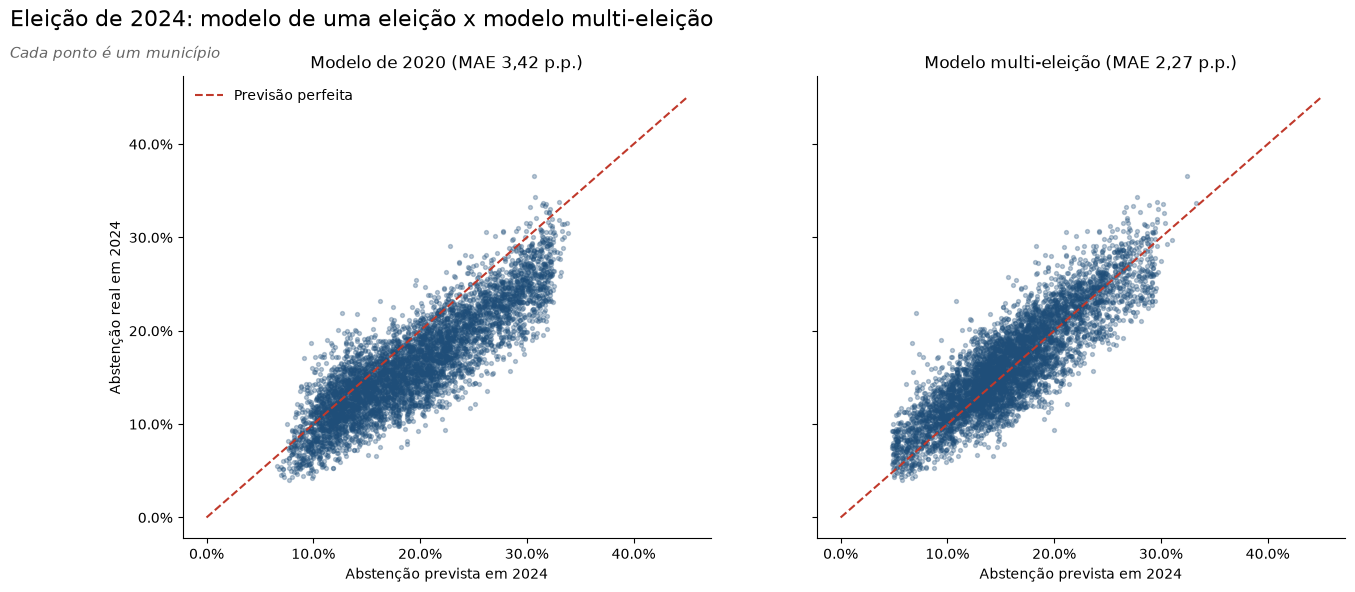

In [58]:
treino_multi = base_modelo_relativo(painel, [2016, 2020])
teste_multi = base_modelo_relativo(painel, [2024])
modelo_multi = clone(modelo_final).fit(treino_multi[FEATURES_RELATIVO], treino_multi['abstencao_relativa'])

previsto_multi = modelo_multi.predict(teste_multi[FEATURES_RELATIVO]) + teste_multi['abstencao_nacional']
real_multi = teste_multi['abstencao']
print(f'Treino: {len(treino_multi):,} linhas (2016 + 2020) | Teste: {len(teste_multi):,} municípios (2024)')

comparacao_2024 = pd.DataFrame({
    'MAE (p.p.)': [mean_absolute_error(real_2024, previsto_2024) * 100, mean_absolute_error(real_multi, previsto_multi) * 100],
    'Viés médio (p.p.)': [vies_2024 * 100, (previsto_multi - real_multi).mean() * 100],
    'R²': [r2_score(real_2024, previsto_2024), r2_score(real_multi, previsto_multi)],
    'Ordenação (Spearman)': [spearmanr(previsto_2024, real_2024)[0], spearmanr(previsto_multi, real_multi)[0]],
}, index=['Modelo de 2020', 'Modelo multi-eleição (2016 + 2020)'])
display(comparacao_2024.round(3))

fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, previsto, real, nome in [(axs[0], previsto_2024, real_2024, 'Modelo de 2020'),
                                 (axs[1], previsto_multi, real_multi, 'Modelo multi-eleição')]:
    ax.scatter(previsto, real, s=8, alpha=0.3, color=COR_PRINCIPAL)
    ax.plot([0, 0.45], [0, 0.45], color=COR_DESTAQUE, ls='--', label='Previsão perfeita')
    ax.set_title(f'{nome} (MAE {pp(mean_absolute_error(real, previsto) * 100)})')
    ax.set_xlabel('Abstenção prevista em 2024')
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axs[0].set_ylabel('Abstenção real em 2024')
axs[0].legend(frameon=False)
sns.despine()
titulo('Eleição de 2024: modelo de uma eleição x modelo multi-eleição', 'Cada ponto é um município')
salvar('Modelo multi-eleicao 2024')
plt.show()

📌 **Nota**
- 🔎 Com o nível nacional tratado à parte, o erro em 2024 cai de **3,42** para **2,27 p.p.** e o R² sobe de **0,40** para **0,73**. O viés passa de **+2,8 p.p.** para **−0,5 p.p.**
- 🔎 A ordenação dos municípios continua a mesma (Spearman de **0,85**): o ganho veio de **acertar o nível**, sem perder a capacidade de comparar cidades.
- ✅ **Decisão:** usar o **modelo multi-eleição para planejar eleições futuras**, informando o nível nacional como cenário, e o modelo de 2020 para **explicar 2020** e encontrar os municípios fora do padrão.

# FASE 05: IMPLANTAÇÃO

## 1 - SALVAR O MODELO E AS TABELAS

In [59]:
joblib.dump({'modelo': modelo_final, 'erro_p10': erro_p10, 'erro_p90': erro_p90, 'features': FEATURES},
            '../Model/modelo_abstencao.pkl')

municipios = mun.merge(situacao, left_on='codigo_tse', right_index=True, how='left')
municipios.to_csv('../Datasets/municipios.csv', index=False)

eleitos = df.loc[df['eleito'], ['codigo_tse', 'uf', 'municipio', 'cargo', 'candidato', 'partido', 'votos']]
eleitos.to_csv('../Datasets/eleitos.csv', index=False)

print(f'municipios.csv: {len(municipios):,} linhas | eleitos.csv: {len(eleitos):,} linhas')

# Modelo multi-eleição para a próxima eleição: treinado com as 3 eleições (2016, 2020 e 2024).
# A faixa de erro vem do teste fora do tempo em 2024 (o cenário mais parecido com prever uma eleição futura).
erros_multi = real_multi - previsto_multi
todas_eleicoes = base_modelo_relativo(painel, [2016, 2020, 2024])
joblib.dump({'modelo': clone(modelo_final).fit(todas_eleicoes[FEATURES_RELATIVO], todas_eleicoes['abstencao_relativa']),
             'features': FEATURES_RELATIVO, 'erro_p10': np.quantile(erros_multi, 0.10),
             'erro_p90': np.quantile(erros_multi, 0.90), 'nivel_ultima_eleicao': teste_multi['abstencao_nacional'].iloc[0]},
            '../Model/modelo_abstencao_multieleicao.pkl')

municipios.csv: 11,133 linhas | eleitos.csv: 63,385 linhas


['../Model/modelo_abstencao_multieleicao.pkl']

📌 **Nota**
- 🔎 `Model/modelo_abstencao.pkl` guarda o **pipeline completo** (transformações + modelo) e a **faixa de erro**, para o app mostrar a previsão com margem.
- 🔎 `Model/modelo_abstencao_multieleicao.pkl` é o modelo **para a próxima eleição**: treinado com 2016, 2020 e 2024, recebe o **nível nacional esperado** como cenário. A faixa de erro vem do teste em 2024.
- 🔎 `eleitos.csv` inclui os candidatos marcados como eleitos (para prefeito, também os que foram ao 2º turno); o app usa a coluna `situacao` de `municipios.csv` para diferenciar.

## 2 - SIMULAÇÃO

In [60]:
modelo_salvo = joblib.load('../Model/modelo_abstencao.pkl')

# Os indicadores do IBGE e a abstenção anterior começam na mediana dos municípios e mudam só onde indicado
mediana = base[FEATURES[1:]].median()
cenarios = pd.DataFrame([
    {'cenário': 'Cidade pequena no Piauí', 'uf': 'PI', 'capital': 0, 'aptos': 8_000,
     'candidatos_prefeito': 2, 'candidatos_por_vaga_vereador': 4, 'abstencao_anterior': 0.12},
    {'cenário': 'Cidade média em Minas Gerais', 'uf': 'MG', 'capital': 0, 'aptos': 80_000,
     'candidatos_prefeito': 5, 'candidatos_por_vaga_vereador': 15, 'abstencao_anterior': 0.18},
    {'cenário': 'Mesma cidade, com abstenção alta em 2016', 'uf': 'MG', 'capital': 0, 'aptos': 80_000,
     'candidatos_prefeito': 5, 'candidatos_por_vaga_vereador': 15, 'abstencao_anterior': 0.28},
]).set_index('cenário')
cenarios['log_aptos'] = np.log10(cenarios['aptos'])
cenarios = cenarios.fillna(mediana)
for coluna in FEATURES[1:]:
    if coluna not in cenarios:
        cenarios[coluna] = mediana[coluna]

previsao = modelo_salvo['modelo'].predict(cenarios[modelo_salvo['features']])
cenarios['abstenção prevista'] = [pct(v, 1) for v in previsao]
cenarios['faixa (80%)'] = [f"{pct(v + modelo_salvo['erro_p10'], 1)} a {pct(v + modelo_salvo['erro_p90'], 1)}"
                           for v in previsao]
cenarios[['uf', 'aptos', 'candidatos_prefeito', 'abstencao_anterior', 'abstenção prevista', 'faixa (80%)']]

,uf,aptos,candidatos_prefeito,abstencao_anterior,abstenção prevista,faixa (80%)
cenário,,,,,,
Cidade pequena no Piauí,PI,8000,2,0.120,"13,4%","10,2% a 16,5%"
Cidade média em Minas Gerais,MG,80000,5,0.180,"22,8%","19,6% a 26,0%"
"Mesma cidade, com abstenção alta em 2016",MG,80000,5,0.280,"30,6%","27,4% a 33,8%"


📌 **Nota**
- 🔎 O modelo salvo reproduz os padrões da análise: uma **cidade pequena no Piauí** tem abstenção esperada de **13,4%**, e uma **cidade média em Minas Gerais**, de **22,8%**.
- 🔎 A mesma cidade mineira, mas com **28%** de abstenção em 2016 (em vez de 18%), passa para **30,6%**: o histórico da cidade é o fator que mais pesa.
- 🔎 Cada previsão vem com a **faixa de 80%**, para deixar claro que é uma estimativa, não um valor exato.

#### Próxima eleição: o mesmo município em 3 cenários nacionais

In [61]:
modelo_multi_salvo = joblib.load('../Model/modelo_abstencao_multieleicao.pkl')
cidade = cenarios.loc[['Cidade média em Minas Gerais']].copy()
cidade['abstencao_anterior_relativa'] = 0.18 - modelo_multi_salvo['nivel_ultima_eleicao']  # 18% na última eleição

proxima = {}
for nome, nivel in [('Igual a 2016 (17,6%)', 0.176), ('Igual a 2024 (21,7%)', 0.217), ('Igual a 2020 (23,1%)', 0.231)]:
    valor = modelo_multi_salvo['modelo'].predict(cidade[modelo_multi_salvo['features']])[0] + nivel
    proxima[nome] = {'abstenção prevista': pct(valor, 1),
                     'faixa (80%)': f"{pct(valor + modelo_multi_salvo['erro_p10'], 1)} a "
                                    f"{pct(valor + modelo_multi_salvo['erro_p90'], 1)}"}
pd.DataFrame(proxima).T.rename_axis('Abstenção nacional no cenário')

,abstenção prevista,faixa (80%)
Abstenção nacional no cenário,,
"Igual a 2016 (17,6%)","15,3%","12,1% a 19,2%"
"Igual a 2024 (21,7%)","19,4%","16,2% a 23,3%"
"Igual a 2020 (23,1%)","20,8%","17,6% a 24,7%"


📌 **Nota**
- 🔎 Para a mesma cidade média mineira, com 18% de abstenção na última eleição, a previsão vai de **15,3%** (cenário nacional igual a 2016) a **19,4%** (igual a 2024) e **20,8%** (igual a 2020).
- 💡 Ela fica **abaixo do nível nacional** nos 3 cenários, porque a cidade teve abstenção menor que a média do país na última eleição (18% contra 21,7%). O modelo transporta essa **diferença própria** do município para o novo cenário.

# 💡 INSIGHTS

| # | Insight | Para quem interessa |
|---|---|---|
| 1 | **A base exigia cuidado:** a coluna "número de eleitores" era a marcação de eleito, os "eleitos" para prefeito incluíam o 2º turno e 7 códigos IBGE estavam trocados. Sem essa checagem, a v1 contou 114 prefeitos a mais e calculou uma abstenção sem sentido | Qualquer analista: **conferir o significado das colunas antes de calcular** |
| 2 | **5 partidos (MDB, PP, PSD, PSDB e DEM) elegeram 57% dos prefeitos e 48% dos vereadores em 2020** | Imprensa e partidos |
| 3 | **De 2016 para 2024, o PSD virou o maior partido (538 → 886 prefeitos) e o PSDB perdeu 2 de cada 3 prefeituras (799 → 271)** | Imprensa e partidos |
| 4 | **Eficiência importa mais que volume:** o PP elegeu 46% dos seus candidatos a prefeito, o PT 15% | Partidos: priorizar onde há chance real |
| 5 | **Quanto maior e mais urbana a cidade, maior a abstenção (13,9% → 25,8%), os brancos e nulos (4,1% → 12,5%) e a concorrência** | Órgãos eleitorais e campanhas em cidades grandes |
| 6 | **A abstenção subiu na pandemia (17,6% → 23,1%) e não voltou em 2024 (21,7%)**, principalmente nas cidades grandes | Órgãos eleitorais |
| 7 | **O partido do prefeito costuma ter a maior bancada (67%), mas raramente a maioria (mediana de 33% das cadeiras)** | Prefeitos eleitos: alianças são necessárias |
| 8 | **A abstenção de uma cidade é muito estável:** com a eleição anterior + tamanho + estado + IBGE, o modelo explica 80% das diferenças entre municípios (erro de 2,0 p.p.) | Órgãos eleitorais: saber onde a abstenção será alta |
| 9 | **O modelo de uma eleição ordena bem os municípios em 2024, mas erra o nível nacional** (viés de +2,8 p.p.). Separando o município do contexto nacional, o **modelo multi-eleição** reduz o erro em 2024 de 3,4 para **2,3 p.p.** | Quem for usar o modelo para planejar a próxima eleição |
| 10 | **Alianças importam:** quem concorreu sozinho venceu 9% das vezes; com 8 ou mais partidos, 67% (em parte porque as alianças se formam em torno dos favoritos) | Partidos: negociar alianças cedo |
| 11 | **A Covid local quase não explica a abstenção entre municípios:** a pandemia elevou a abstenção no país todo, de forma geral | Órgãos eleitorais: comunicação nacional, não só local |

# 🚀 PRÓXIMOS PASSOS

1. **Prever o nível nacional** da próxima eleição (ex.: com a série histórica desde 2000 e indicadores de interesse, como buscas na internet), em vez de tratá-lo como cenário.
2. **Acrescentar escolaridade** (Censo 2022) e a **distância média até as seções eleitorais**, para explicar parte da abstenção que o modelo ainda não explica.
3. **Coligações com controle de favoritismo:** comparar candidatos parecidos (mesmo partido, cidades de tamanho parecido) com e sem aliança, para medir o efeito da aliança e não só a correlação.
4. **Estudar o recadastramento biométrico**, que cancelou títulos e pode explicar parte das mudanças de abstenção em alguns estados.
5. **Publicar o app** no Streamlit Community Cloud e gravar um GIF para o README.

# 🖥️ Interface com Streamlit

Para que qualquer pessoa explore os resultados **sem abrir o notebook**, criamos um app em **Streamlit** com 4 abas:
1. **Painel:** escolhe o Brasil ou um estado e vê eleitores, abstenção, brancos/nulos, um **mapa interativo** (abstenção, brancos/nulos ou partido com mais prefeitos) e os partidos que mais elegeram.
2. **Município:** escolhe uma cidade e vê o prefeito eleito (ou o resultado do 2º turno e do julgamento), a composição da Câmara, a abstenção **real × esperada** pelo modelo e a abstenção de 2016, 2020 e 2024.
3. **2016 → 2024:** prefeitos eleitos por partido nas 3 eleições e a abstenção de cada uma.
4. **Simulador:** informa o perfil de um município e recebe a **abstenção esperada**, com a faixa de erro. Pode usar o modelo de 2020 ou o **modelo multi-eleição**, informando a abstenção nacional esperada para a próxima eleição.

A célula abaixo grava o arquivo `app.py` na raiz do projeto. Para executar (a partir da raiz):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [62]:
%%writefile ../app.py
"""App Streamlit: painel das eleições municipais (1º turno de 2020, com 2016 e 2024) e simulador de abstenção."""
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st

RAIZ = Path(__file__).resolve().parent
sys.path.append(str(RAIZ))
from src.eleicao import base_modelo  # noqa: E402

st.set_page_config(page_title='Eleições municipais 2020', page_icon='🗳️', layout='wide')


@st.cache_data
def carregar_dados():
    pasta = RAIZ / 'Datasets'
    municipios = pd.read_csv(pasta / 'municipios.csv')
    eleitos = pd.read_csv(pasta / 'eleitos.csv')
    painel = pd.read_csv(pasta / 'painel_municipios_2016_2024.csv')
    prefeitos_final = pd.read_csv(pasta / 'prefeitos_eleitos_2016_2024.csv')
    with open(pasta / 'uf.json', encoding='utf-8') as arquivo:
        mapa_uf = json.load(arquivo)
    return municipios, eleitos, painel, prefeitos_final, mapa_uf


@st.cache_resource
def carregar_modelos():
    pasta = RAIZ / 'Model'
    return joblib.load(pasta / 'modelo_abstencao.pkl'), joblib.load(pasta / 'modelo_abstencao_multieleicao.pkl')


def pct(valor):
    return f'{valor:.1%}'.replace('.', ',')


def milhar(valor):
    return f'{valor:,.0f}'.replace(',', '.')


municipios, eleitos, painel, prefeitos_final, mapa_uf = carregar_dados()
artefato, artefato_multi = carregar_modelos()
modelo = artefato['modelo']
prefeito = municipios[municipios['cargo'] == 'prefeito']
base_2020 = base_modelo(painel, 2020)

st.title('🗳️ Eleições municipais 2020: 1º turno')
st.caption('Dados abertos do TSE e do IBGE · 5.566 municípios com eleição para prefeito · '
           'Projeto de portfólio de Rafael R. Silva')

aba_painel, aba_municipio, aba_evolucao, aba_simulador = st.tabs(
    ['📊 Painel', '🏙️ Município', '📈 2016 → 2024', '🔮 Simulador de abstenção'])

# ----------------------------------------------------------------------------- Painel
with aba_painel:
    uf = st.selectbox('Região', ['Brasil'] + sorted(prefeito['uf'].unique()), key='uf_painel')
    filtro_mun = prefeito if uf == 'Brasil' else prefeito[prefeito['uf'] == uf]
    situacao_ok = filtro_mun.loc[filtro_mun['situacao'] == 'Eleito no 1º turno', 'codigo_tse']
    eleitos_uf = eleitos[eleitos['codigo_tse'].isin(filtro_mun['codigo_tse'])]

    col1, col2, col3, col4 = st.columns(4)
    col1.metric('Municípios', milhar(len(filtro_mun)))
    col2.metric('Eleitores aptos', milhar(filtro_mun['aptos'].sum()))
    col3.metric('Abstenção', pct(filtro_mun['abstencoes'].sum() / filtro_mun['aptos'].sum()))
    col4.metric('Brancos + nulos (prefeito)',
                pct((filtro_mun['votos_brancos'] + filtro_mun['votos_nulos']).sum() / filtro_mun['total_votos'].sum()))

    st.caption('Situação da disputa para prefeito no 1º turno: '
               + ' · '.join(f'{k}: {v}' for k, v in filtro_mun['situacao'].value_counts().items()))

    # Mapa interativo por estado
    indicador = st.radio('Indicador do mapa', ['Abstenção', 'Brancos + nulos (prefeito)', 'Partido com mais prefeitos'],
                         horizontal=True)
    por_uf = prefeito.groupby('uf')[['abstencoes', 'aptos', 'votos_brancos', 'votos_nulos', 'total_votos']].sum()
    por_uf['Abstenção'] = por_uf['abstencoes'] / por_uf['aptos']
    por_uf['Brancos + nulos (prefeito)'] = (por_uf['votos_brancos'] + por_uf['votos_nulos']) / por_uf['total_votos']
    final_2020 = prefeitos_final[prefeitos_final['ano'] == 2020]
    por_uf['Partido com mais prefeitos'] = final_2020.groupby('uf')['partido_original'].agg(
        lambda s: s.value_counts().index[0])
    por_uf = por_uf.reset_index()

    opcoes_mapa = dict(geojson=mapa_uf, locations='uf', featureidkey='properties.UF_05', color=indicador,
                       hover_name='uf', fitbounds='locations', height=520)
    if indicador == 'Partido com mais prefeitos':
        figura = px.choropleth(por_uf, **opcoes_mapa)
    else:
        figura = px.choropleth(por_uf, color_continuous_scale='YlOrRd', hover_data={indicador: ':.1%'}, **opcoes_mapa)
        figura.update_coloraxes(colorbar_tickformat='.0%')
    figura.update_geos(visible=False)
    figura.update_layout(margin={'l': 0, 'r': 0, 't': 0, 'b': 0})
    st.plotly_chart(figura, width='stretch')
    st.caption('"Partido com mais prefeitos" usa o resultado final de 2020 (inclui o 2º turno). '
               'O DF não tem eleição municipal.')

    col_a, col_b = st.columns(2)
    prefeitos_partido = (eleitos_uf[(eleitos_uf['cargo'] == 'prefeito') & eleitos_uf['codigo_tse'].isin(situacao_ok)]
                         ['partido'].value_counts().head(10))
    vereadores_partido = eleitos_uf[eleitos_uf['cargo'] == 'vereador']['partido'].value_counts().head(10)
    col_a.subheader('Prefeitos eleitos no 1º turno (top 10)')
    col_a.bar_chart(prefeitos_partido, horizontal=True, color='#1F4E79')
    col_b.subheader('Vereadores eleitos (top 10)')
    col_b.bar_chart(vereadores_partido, horizontal=True, color='#C0392B')

# ----------------------------------------------------------------------------- Município
with aba_municipio:
    col_uf, col_cidade = st.columns([1, 3])
    uf_mun = col_uf.selectbox('Estado', sorted(prefeito['uf'].unique()), key='uf_mun')
    cidades = prefeito[prefeito['uf'] == uf_mun].sort_values('municipio')
    nome = col_cidade.selectbox('Município', cidades['municipio'])
    cidade = cidades[cidades['municipio'] == nome].iloc[0]
    codigo = cidade['codigo_tse']

    st.subheader(f"{nome} ({uf_mun}) · {cidade['situacao']}")
    eleitos_cidade = eleitos[eleitos['codigo_tse'] == codigo]
    candidatos_prefeito = eleitos_cidade[eleitos_cidade['cargo'] == 'prefeito'].sort_values('votos', ascending=False)
    final = prefeitos_final[(prefeitos_final['ano'] == 2020) & (prefeitos_final['codigo_tse'] == codigo)]

    if cidade['situacao'] == 'Eleito no 1º turno':
        eleito = candidatos_prefeito.iloc[0]
        st.success(f"Prefeito eleito: **{eleito['candidato']}** ({eleito['partido']}) com {milhar(eleito['votos'])} votos")
    elif cidade['situacao'] == '2º turno':
        nomes = ' x '.join(f"**{c['candidato']}** ({c['partido']})" for _, c in candidatos_prefeito.iterrows())
        vencedor = f" · Venceu no 2º turno: **{final['partido_original'].iloc[0]}**" if len(final) else ''
        st.info(f'Foram para o 2º turno: {nomes}{vencedor}')
    else:
        resultado = (f"Depois do julgamento, o TSE registrou como eleito o candidato do "
                     f"**{final['partido_original'].iloc[0]}**." if len(final)
                     else 'Não há prefeito eleito registrado na eleição ordinária (o cargo foi decidido em eleição suplementar).')
        st.warning(f'Resultado indefinido no 1º turno (candidatura sub judice). {resultado}')

    if codigo in base_2020.index:
        linha = base_2020.loc[[codigo]]
        esperada = modelo.predict(linha[artefato['features']])[0]
        col1, col2, col3 = st.columns(3)
        col1.metric('Eleitores aptos', milhar(cidade['aptos']))
        col2.metric('Abstenção real', pct(cidade['abstencao']),
                    delta=f"{(cidade['abstencao'] - esperada) * 100:+.1f}".replace('.', ',') + ' p.p. vs esperado',
                    delta_color='inverse')
        col3.metric('Abstenção esperada pelo modelo', pct(esperada))
        st.caption('O modelo foi treinado com quase todos os municípios, incluindo este; a comparação é ilustrativa.')

        historico = painel[painel['codigo_tse'] == codigo].set_index('ano')['abstencao']
        st.write('**Abstenção nas 3 eleições municipais:** '
                 + ' · '.join(f'{ano}: {pct(valor)}' for ano, valor in historico.items()))

    camara = eleitos_cidade[eleitos_cidade['cargo'] == 'vereador']['partido'].value_counts()
    if len(camara):
        st.subheader(f'Composição da Câmara Municipal ({camara.sum()} cadeiras)')
        st.bar_chart(camara, horizontal=True, color='#1F4E79')

# ----------------------------------------------------------------------------- Evolução
with aba_evolucao:
    st.write('Prefeitos eleitos por partido (resultado final, com 2º turno). Partidos que se fundiram aparecem com o '
             'nome atual: **UNIÃO** = DEM + PSL, **PRD** = PTB + Patriota, **PODE** inclui o PSC.')
    evolucao = prefeitos_final.pivot_table(index='partido', columns='ano', aggfunc='size', fill_value=0)
    evolucao = evolucao.sort_values(2024, ascending=False).head(12)
    st.bar_chart(evolucao.rename(columns=str), stack=False, horizontal=True, height=520)

    nacional = painel.groupby('ano')[['abstencoes', 'aptos']].sum()
    colunas = st.columns(len(nacional))
    for coluna, (ano, linha) in zip(colunas, nacional.iterrows()):
        coluna.metric(f'Abstenção em {ano}', pct(linha['abstencoes'] / linha['aptos']))

# ----------------------------------------------------------------------------- Simulador
with aba_simulador:
    st.write('Informe o perfil de um município para estimar a **abstenção esperada**. '
             'Os valores iniciais são os do município típico (mediana).')
    tipo_modelo = st.radio('Modelo', ['Padrão de 2020', 'Próxima eleição (multi-eleição)'], horizontal=True,
                           help='O modelo multi-eleição foi treinado com 2016, 2020 e 2024 e recebe a abstenção '
                                'nacional esperada como cenário.')
    mediana = base_2020.median(numeric_only=True)
    col1, col2, col3 = st.columns(3)
    uf_sim = col1.selectbox('Estado', sorted(prefeito['uf'].unique()), key='uf_sim')
    aptos = col1.number_input('Eleitores aptos', min_value=1_000, max_value=9_000_000, value=20_000, step=1_000)
    capital = col1.checkbox('É capital do estado')
    candidatos = col2.slider('Candidatos a prefeito', 1, 20, 3)
    por_vaga = col2.slider('Candidatos a vereador por vaga', 1.0, 40.0, 8.0, step=0.5)
    anterior = col2.slider('Abstenção do município na eleição anterior', 0.0, 0.40,
                           float(round(mediana['abstencao_anterior'], 2)), step=0.01, format='%.2f')
    pib = col3.number_input('PIB per capita (R$)', min_value=3_000, max_value=500_000,
                            value=int(round(10 ** mediana['log_pib_per_capita'], -3)), step=1_000)
    urbana = col3.slider('Parcela da população urbana', 0.0, 1.0, float(round(mediana['pct_urbana'], 2)),
                         step=0.01, format='%.2f')
    idosos = col3.slider('Parcela da população com 60 anos ou mais', 0.05, 0.40,
                         float(round(mediana['pct_idosos'], 2)), step=0.01, format='%.2f')
    por_habitante = col3.slider('Eleitores por habitante', 0.3, 1.5,
                                float(round(mediana['eleitores_por_habitante'], 2)), step=0.01)

    entrada = pd.DataFrame([{'uf': uf_sim, 'capital': int(capital), 'log_aptos': np.log10(aptos),
                             'candidatos_prefeito': candidatos, 'candidatos_por_vaga_vereador': por_vaga,
                             'log_pib_per_capita': np.log10(pib), 'pct_urbana': urbana, 'pct_idosos': idosos,
                             'eleitores_por_habitante': por_habitante, 'abstencao_anterior': anterior}])
    if tipo_modelo == 'Padrão de 2020':
        escolhido = artefato
        previsao = modelo.predict(entrada[artefato['features']])[0]
    else:
        escolhido = artefato_multi
        nivel = st.slider('Abstenção nacional esperada na próxima eleição', 0.10, 0.30,
                          float(round(artefato_multi['nivel_ultima_eleicao'], 3)), step=0.005, format='%.3f',
                          help='Referências: 17,6% em 2016, 23,1% em 2020 e 21,7% em 2024.')
        # A abstenção anterior do município é comparada ao nível nacional da última eleição (2024)
        entrada['abstencao_anterior_relativa'] = anterior - artefato_multi['nivel_ultima_eleicao']
        previsao = artefato_multi['modelo'].predict(entrada[artefato_multi['features']])[0] + nivel
    st.metric('Abstenção esperada', pct(previsao))
    st.caption(f"Em 80% dos casos, a abstenção real ficou entre {pct(previsao + escolhido['erro_p10'])} e "
               f"{pct(previsao + escolhido['erro_p90'])} para um perfil como este.")

    media_uf = prefeito[prefeito['uf'] == uf_sim]
    st.caption(f"Para comparação: a abstenção em {uf_sim} foi de "
               f"{pct(media_uf['abstencoes'].sum() / media_uf['aptos'].sum())}.")

Overwriting ../app.py
